# Steering an LLM to vary its search algorithms: a de-commitment steering screen on Qwen3-8B (demo)

**Question.** Asked to *"write a shortest-path function"*, does an LLM always write the same algorithm, and can we push it toward others **from inside the model**? This experiment tests one idea, *de-commitment*. A residual-stream direction separates "brainstorm several approaches" prompts from "just implement it" prompts. If we add that direction while the model writes code, does it produce a **wider variety of correct algorithms**?

**Setup.** Qwen3-8B, thinking off, temperature 1, top-p 1, top-k off, the same scaffold for every arm.
* **Tasks.** Two path-search tasks with hidden tests and known algorithm catalogues:
  * **T1, grid path**: BFS, DFS, bidirectional BFS, IDDFS, A*, Dijkstra.
  * **T2, weighted shortest path**: Dijkstra, Bellman-Ford/SPFA, bidirectional Dijkstra, Floyd-Warshall, Dial.
* **Direction.** `d_dc = mean(h_R | LIST frame) − mean(h_R | IMPLEMENT frame)`, from 50 + 50 frame paraphrases. `h_R` is the residual state at the last prompt token R, at layer L* = 18 of 36.
* **Intervention.** Add `c·‖h‖·d̂` at R and at every generated token. c* is the largest c whose pass rate stays at least 0.8 × the unsteered rate; it is chosen on pass rate only.
* **Outcome.** The Hill-1 number (effective number of distinct algorithms) of the labels of **correct** programs. Labels come from sandboxed hidden tests, a runtime tracer and AST rules, with an LLM judge for disagreements.
* **Controls.** Zero-strength hook (HF c=0), vLLM baseline (N = 200), two random directions, a variable-name placebo direction, a breadth direction, cross-task transfer, the enumeration prompt ("list 10 approaches, then implement one"), modal-mode ban and mention prompts, and a succession ban.

**Full-run result (screen verdict PARTIAL).**
* T1 is 100 % BFS in every arm except the bans.
* On T2 at c* = 0.25, the correct programs move from Dijkstra to Bellman-Ford: 88 D / 7 BF at c = 0 against 23 D / 54 BF at c*. Rarefied ΔHill-1 is +0.65, with a 90 % cluster CI of [0.31, 0.97].
* A random direction at the same strength does almost the same, so the gain is **not direction-specific**. A prompt ban buys diversity more cheaply.

**What this notebook runs.** The original `method.py` is an orchestrator: it runs 17 stages as separate scripts. Its GPU stages (R-state extraction, vLLM and HF generation with the steering hook) took about 2 GPU-hours on an RTX A4500, which a demo cannot repeat. The notebook ships the **outputs of those GPU stages for task T2** in `mini_demo_data.json`:
* the residual states at R;
* the generated programs with their sandbox labels: 100 common-random-number slots × 19 arms = 1,670 samples.

It then **re-executes the CPU stages of the pipeline with the original functions**:
1. the prompt scaffold;
2. direction finding, layer selection and the forward-pass commitment test;
3. the steering hook's arithmetic, replayed on real R-states;
4. the static (AST) algorithm labeller;
5. the c* rule, the modal mode and the hash-committed forecasts;
6. every statistic and the pre-registered screen verdict;
7. the figures, plus activation-space geometry plots.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (every original script logs with it)
_pip('loguru==0.7.3')

# numpy, pandas, scipy, scikit-learn, statsmodels, matplotlib, torch — pre-installed on Colab, install locally only
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'pandas==2.2.2', 'scipy==1.16.3', 'scikit-learn==1.6.1', 'statsmodels==0.14.6',
         'matplotlib==3.10.0')
    _pip('torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu')  # Colab's torch version, CPU wheel

In [2]:
from __future__ import annotations

# ---- the original import blocks of method.py, common.py, analysis/{directions,stats,analyze,forecast,figures}.py,
#      analysis/audit_commitment_perm.py, labeller/{ast_rules,label}.py and gpu/hf_steer.py ----
import ast
import hashlib
import itertools
import json
import math
import re
import sys
import time
from collections import Counter
from pathlib import Path

import numpy as np
import torch
from loguru import logger
from sklearn.metrics import roc_auc_score

import matplotlib
import matplotlib.pyplot as plt

# ---- added for the notebook: decoding the shipped float16 arrays, a namespace for the `S.<stat>` calls, tables ----
import base64
import types

import pandas as pd
from IPython.display import display

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-1/experiment-4/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
dset = data["datasets"][0]
print(f"dataset {dset['dataset']}: {len(dset['examples'])} common-random-number slots, "
      f"{sum(len(e['arms']) for e in dset['examples'])} labelled samples over "
      f"{len({c for e in dset['examples'] for c in e['arms']})} arms")
print(f"R-state groups: {len(data['activations']['groups'])}; model: {data['metadata']['model']} "
      f"({data['metadata']['thinking']})")
print("first example (CRN slot) fields:", [k for k in dset["examples"][0] if not k.startswith("predict_")],
      "+", sum(k.startswith("predict_") for k in dset["examples"][0]), "predict_<arm> fields")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
dataset T2_weighted_shortest_path: 100 common-random-number slots, 1670 labelled samples over 19 arms
R-state groups: 18; model: Qwen/Qwen3-8B (off (enable_thinking=False))
first example (CRN slot) fields: ['input', 'output', 'metadata_task', 'metadata_paraphrase_id', 'metadata_sample_id', 'metadata_reference_condition', 'metadata_reference_passed', 'metadata_catalogue', 'arms'] + 18 predict_<arm> fields


## Configuration

The data and every decision rule are those of the full run. The tunable parameters below only set **how many resamples, permutations and random vectors** the statistics use. They are set to the **original full-run values**, and the notebook still runs in about a minute on a 2-CPU machine; the cell lists lower values for a ~10 s smoke test.

At these values, every statistic referenced to HF c=0 reproduces the full run exactly. That covers the steering arms, the specificity test and the commitment test. Statistics referenced to the vLLM baseline differ somewhat, because the demo ships the baseline's 100 CRN slots (paraphrases 0-9) rather than all 200 samples.

In [5]:
# ---------------- tunable parameters (set to the original full-run values) ----------------
# The whole notebook runs in about a minute on 2 CPUs at these values. For a ~10 s smoke test use e.g.
# NB = 10, N_REP_RAREFY = 2, N_REP_RAREFY_POINT = 10, N_SHIFT_NULL = 50, N_SPLIT_HALF = 5, N_RAND_UNIT = 20,
# N_PERM = 50, N_MC = 100 (pass rates, label counts, c* and delta kappa stay exact; CIs and p-values get coarse).
TASKS = ["T2"]             # tasks analysed (original: ["T1", "T2"]; the demo data ships T2 only)
NB = 2000                  # bootstrap resamples behind every 90% CI (original analyze.py: NB = 2000)
N_REP_RAREFY = 30          # rarefaction draws inside each bootstrap replicate (original: 30)
N_REP_RAREFY_POINT = 1000  # rarefaction draws for the rarefied Hill-1 point estimates (original: 1000)
N_SHIFT_NULL = 2000        # random 10/10 paraphrase splits behind the commitment null band (original: 2000)
N_SPLIT_HALF = 200         # split-half repeats of the direction-stability check (original: 200)
N_RAND_UNIT = 1000         # random unit vectors for the share-of-shift percentiles (original: 1000)
N_PERM = 20000             # label permutations in the commitment audit (original: 20000)
N_MC = 20000               # Monte-Carlo permutations of the exact test for 2 x K tables (original: 20000)

## The pipeline in `method.py`

`method.py` runs 17 stages in order. Each stage is one script started as its own process (`run([script, ...])`), and each stage skips work already on disk, so the pipeline resumes. GPU stages never load vLLM and HF together. Its dispatcher looks like this (abridged):

```python
def stage(name: str) -> None:
    if name == "prompts":      run(["prompts/make_paraphrases.py"], ...)
    elif name == "tasks":      run(["tasks/build_tests.py", *reuse], ...)        # hidden tests + R0 gate
    elif name == "states":     run(["gpu/hf_states.py"], ...)                    # R-states (GPU)
    elif name == "directions": run(["analysis/directions.py"], ...)              # d_dc, L*, commitment test
    elif name == "vllm1":      run(["gpu/vllm_gen.py", "--session", "s1"], ...)  # baseline + enumerate (GPU)
    elif name == "steer":      run(["gpu/hf_steer.py", "--budget-min", "125"], ...)  # steering arms (GPU) + label daemon
    elif name == "label":      run(["labeller/daemon.py", "--once"], ...); run(["labeller/judge.py", "--bulk", "--cap", "0.80"], ...)
    elif name == "gate":       run(["labeller/gate.py"], ...)
    elif name == "commit":     run(["analysis/forecast.py", "modal"], ...); run(["analysis/forecast.py", "commit-ban"], ...)
    elif name == "vllm2":      run(["gpu/vllm_gen.py", "--session", "s2", "--with-mention"], ...)  # ban + mention (GPU)
    elif name == "succ":       run(["analysis/forecast.py", "commit-succ"], ...)
    elif name == "vllm3":      run(["gpu/vllm_gen.py", "--session", "s3"], ...)  # succession ban (GPU)
    elif name == "analyze":    run(["analysis/forecast.py", "verify"], ...); run(["analysis/analyze.py"], ...)
                               run(["analysis/figures.py"], ...); run(["analysis/method_out.py"], ...)
```

| stage | original script | engine | in this notebook |
|---|---|---|---|
| prompts | `prompts/make_paraphrases.py`, `prompts/scaffold.py` | CPU | **re-run** (scaffold on the shipped paraphrases) |
| tasks | `tasks/build_tests.py` | CPU sandbox | not re-run: it executes model-written code in a sandbox; pass/fail is shipped |
| states | `gpu/hf_states.py` | GPU | output shipped (R-states at R) |
| directions | `analysis/directions.py` | CPU | **re-run** (layer selection, diagnostics, commitment test) + `analysis/audit_commitment_perm.py` |
| vllm1 / vllm2 / vllm3 | `gpu/vllm_gen.py` | GPU | outputs shipped (programs + labels) |
| steer | `gpu/hf_steer.py` | GPU | hook arithmetic **replayed** on R-states; the c* rule **re-run** on the labels |
| label / gate | `labeller/*.py` | CPU + LLM judge | AST rules + `combine()` **re-run**; runtime-tracer and judge labels shipped |
| commit / succ | `analysis/forecast.py` | CPU | **re-run**: modal mode, forecasts, sha256 verification |
| analyze | `analysis/analyze.py`, `analysis/figures.py` | CPU | **re-run** (all statistics, the verdict, the figures) |

In [6]:
# method.py: the end-to-end stage order ("label" runs after every generation wave)
STAGES = ["meta", "prompts", "tasks", "states", "directions", "vllm1", "label", "steer", "label", "gate", "commit",
          "vllm2", "label", "succ", "vllm3", "label", "analyze"]
print(" -> ".join(STAGES))

meta -> prompts -> tasks -> states -> directions -> vllm1 -> label -> steer -> label -> gate -> commit -> vllm2 -> label -> succ -> vllm3 -> label -> analyze


## Shared constants (`common.py`)

These are the task specs and the algorithm catalogues with their display names (used inside ban and mention prompts) and definitions. They also include the lexicon behind `names_mentioned` and the deterministic `stable_hash` that seeds every random choice: vLLM request seeds, HF common random numbers, random directions and bootstrap seeds.

Only the workspace paths, RAM limits and the rotating file logger are dropped, because the notebook keeps everything in memory. `LAYERS` and `TASKS` come from the shipped data and from the config cell.

In [7]:
# ---- common.py (paths / RAM-limit / file-sink helpers dropped; LAYERS and TASKS are set from the data / config) ----
MODEL_ID = "Qwen/Qwen3-8B"
N_LAYERS = 36
GRID_C = [0.25, 0.5, 1.0, 1.5]        # steering coefficient grid (c = 0 is the zero-strength control)
PAD_ID = 151643
EOS_IDS = [151645, 151643]

SPEC = {
    "T1": (
        "Task: write a Python function solve(grid, start, goal). grid is a list of equal-length strings in which . "
        "is an open cell and # is a wall; start and goal are (row, col) tuples of open cells. A move goes up, down, "
        "left or right to an open cell inside the grid. Return any valid path from start to goal as a list of "
        "(row, col) tuples that begins with start, ends with goal and in which consecutive cells are adjacent; "
        "return [] if goal cannot be reached. Grids have at most 30 rows and 30 columns. Use only the Python "
        "standard library. Return only one ```python code block containing solve."
    ),
    "T2": (
        "Task: write a Python function solve(n, edges, s, t). The graph is directed with nodes 0..n-1 (n <= 100); "
        "edges is a list of (u, v, w) tuples with integer weights 0 <= w <= 100; parallel edges, self-loops and "
        "cycles may occur. Return the length of a shortest path from s to t as an int, or -1 if t is unreachable "
        "from s (0 when s == t). Use only the Python standard library. Return only one ```python code block "
        "containing solve."
    ),
}

# Catalogue modes per task (label ids) and the display names used inside ban / mention prompts.
CATALOGUE = {
    "T1": ["bfs", "dfs", "bidirectional_bfs", "iddfs", "astar", "dijkstra_unit"],
    "T2": ["dijkstra", "bellman_ford_spfa", "bidirectional_dijkstra", "floyd_warshall", "dial"],
}
DISPLAY = {
    "T1": {
        "bfs": "breadth-first search (BFS)",
        "dfs": "depth-first search (DFS)",
        "bidirectional_bfs": "bidirectional BFS",
        "iddfs": "iterative-deepening DFS",
        "astar": "A* search",
        "dijkstra_unit": "Dijkstra's algorithm",
    },
    "T2": {
        "dijkstra": "Dijkstra's algorithm",
        "bellman_ford_spfa": "the Bellman-Ford algorithm (including SPFA)",
        "bidirectional_dijkstra": "bidirectional Dijkstra",
        "floyd_warshall": "the Floyd-Warshall algorithm",
        "dial": "Dial's algorithm (bucket queue)",
    },
}
DEFINITIONS = {
    "T1": {
        "bfs": "breadth-first search with a FIFO queue (deque or list.pop(0)), recursive or iterative",
        "dfs": "depth-first search with a LIFO stack or plain recursion, no outer depth-limit loop",
        "bidirectional_bfs": "two simultaneous breadth-first frontiers, one from start and one from goal, that meet",
        "iddfs": "iterative deepening: repeated depth-limited DFS from start with an increasing depth limit",
        "astar": "best-first search on a heap keyed by g+h or h with h = Manhattan distance to goal (A* or greedy best-first)",
        "dijkstra_unit": "uniform-cost search / Dijkstra on a heap keyed by path length g only (no heuristic)",
    },
    "T2": {
        "dijkstra": "Dijkstra's algorithm with one priority queue (heap), nodes popped in non-decreasing distance",
        "bellman_ford_spfa": "Bellman-Ford edge relaxation in repeated passes, or SPFA (FIFO queue with re-enqueueing)",
        "bidirectional_dijkstra": "two Dijkstra searches, forward from s and backward from t on reversed edges, that meet",
        "floyd_warshall": "all-pairs Floyd-Warshall triple loop dist[i][j] = min(dist[i][j], dist[i][k] + dist[k][j])",
        "dial": "Dial's algorithm: Dijkstra with an array of buckets indexed by distance instead of a heap",
    },
}
# Case-insensitive lexicon used for names_mentioned (prose + code comments).
LEXICON = {
    "bfs": [r"\bbfs\b", r"breadth[- ]first"],
    "dfs": [r"\bdfs\b", r"depth[- ]first"],
    "iddfs": [r"iterative[- ]deepening", r"\biddfs\b"],
    "astar": [r"\ba\*", r"\ba-star\b", r"\bastar\b", r"best[- ]first"],
    "dijkstra": [r"dijkstra"],
    "bidirectional": [r"bidirectional", r"bi-directional"],
    "bellman_ford_spfa": [r"bellman", r"\bspfa\b", r"shortest path faster"],
    "floyd_warshall": [r"floyd", r"warshall"],
    "dial": [r"\bdial\b", r"\bdial'?s\b", r"bucket queue"],
}
# Map lexicon keys onto catalogue modes of each task.
LEXICON_TO_MODE = {
    "T1": {"bfs": "bfs", "dfs": "dfs", "iddfs": "iddfs", "astar": "astar", "dijkstra": "dijkstra_unit",
           "bidirectional": "bidirectional_bfs"},
    "T2": {"dijkstra": "dijkstra", "bellman_ford_spfa": "bellman_ford_spfa", "floyd_warshall": "floyd_warshall",
           "dial": "dial", "bidirectional": "bidirectional_dijkstra"},
}


def stable_hash(*parts: object) -> int:
    """Deterministic 31-bit seed from arbitrary parts (independent of PYTHONHASHSEED)."""
    h = hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest()
    return int(h[:8], 16) % (2**31 - 1)


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8", errors="replace")).hexdigest()


def setup_logger(name: str, level: str = "INFO") -> None:
    logger.remove()
    logger.add(sys.stdout, level=level, format="{time:HH:mm:ss}|{level:<7}|{message}")
    # original also adds a rotating file sink: logger.add(str(LOGS_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def cond_name_steer(direction: str, coef: float, layer: int) -> str:
    return f"steer:{direction}:c={coef:g}:L={layer}"


setup_logger("code_demo")
print("seed of the HF batch for T2 paraphrase 0 (common random numbers):", stable_hash("T2", 0))

seed of the HF batch for T2 paraphrase 0 (common random numbers): 935703011


## Stage `prompts`: the prompt scaffold (`prompts/scaffold.py`)

Every prompt is one user turn: `segment + blank line + SPEC[task]`. It goes through the Qwen3 chat template with `enable_thinking=False` and no system message. The template ends with the assistant header and the empty think block (`TEMPLATE_TAIL`). The **read position R is the last token**, and every prompt of a task ends with exactly the same tokens (`check_suffix` asserts this for all 930 prompts). So any difference between conditions at R comes from the instruction segment, not from the tokens at R.

The prompt groups are of two kinds:
* **Direction frames** (50 paraphrases each): `LIST` (brainstorm approaches, no code) against `IMPLEMENT` (just implement it) gives `d_dc`. `ONE` (pick one method) gives the breadth direction, and `LONGNAMES` / `SHORTNAMES` give the variable-name placebo.
* **Behavioural arms**: `baseline`, `enumerate`, `listall`, `ban:X`, `mention:X` and `succession`.

Tokenising needs the Qwen3 tokenizer, so `build_prompt` and `check_suffix` are not re-run here. The segments and user turns below are the exact text the model received.

In [8]:
# ---- prompts/scaffold.py (paraphrases() reads the shipped prompts/paraphrases.json) ----
TEMPLATE_TAIL = "<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n"


def paraphrases() -> dict[str, list[str]]:
    return data["paraphrases"]  # original: json.loads((PROMPTS_DIR / "paraphrases.json").read_text())


def segments(task: str, group: str) -> list[str]:
    """Return the list of instruction segments for a prompt group.

    group in {baseline, enumerate, listall, LIST, IMPLEMENT, ONE, LONGNAMES, SHORTNAMES,
    ban:<mode>, mention:<mode>, succession:<mode1>+<mode2>}.
    """
    P = paraphrases()
    if group.startswith("ban:"):
        x = DISPLAY[task][group.split(":", 1)[1]]
        return [t.replace("{X}", x) for t in P["ban"]]
    if group.startswith("mention:"):
        x = DISPLAY[task][group.split(":", 1)[1]]
        return [t.replace("{X}", x) for t in P["mention"]]
    if group.startswith("succession:"):
        m1, m2 = group.split(":", 1)[1].split("+")
        x = f"{DISPLAY[task][m1]} or {DISPLAY[task][m2]}"
        return [t.replace("{X}", x) for t in P["ban"]]
    return list(P[group])


def user_text(segment: str, task: str) -> str:
    return segment + "\n\n" + SPEC[task]


def all_groups(task: str) -> list[str]:
    g = ["LIST", "IMPLEMENT", "ONE", "LONGNAMES", "SHORTNAMES", "baseline", "enumerate", "listall"]
    g += [f"ban:{m}" for m in CATALOGUE[task]] + [f"mention:{m}" for m in CATALOGUE[task]]
    return g


display(pd.DataFrame([{"group": g, "n paraphrases": len(segments("T2", g)), "paraphrase 0": segments("T2", g)[0]}
                      for g in all_groups("T2") + ["succession:dijkstra+bellman_ford_spfa"]]))
print("User turn of baseline paraphrase 0 (then the chat template appends ...", repr(TEMPLATE_TAIL), "):\n")
print(user_text(segments("T2", "baseline")[0], "T2"))

,group,n paraphrases,paraphrase 0
0,LIST,50,Brainstorm 10 distinct approaches for the task below. Do not write any code.
1,IMPLEMENT,50,Produce a correct implementation to this task. Just implement it.
2,ONE,50,Choose the most appropriate method for solving this task. Do not write any c...
3,LONGNAMES,50,"Choose verbose, self-explanatory names for all variables in your code."
4,SHORTNAMES,50,"Use short, terse variable names in your code."
5,baseline,20,Solve the following programming task.
6,enumerate,10,"First list 10 different approaches to this task, then implement one of them."
7,listall,10,List all the approaches you can think of for this task. Do not implement any...
8,ban:dijkstra,10,Do not use Dijkstra's algorithm.
9,ban:bellman_ford_spfa,10,Do not use the Bellman-Ford algorithm (including SPFA).


User turn of baseline paraphrase 0 (then the chat template appends ... '<|im_end|>\n<|im_start|>assistant\n<think>\n\n</think>\n\n' ):

Solve the following programming task.

Task: write a Python function solve(n, edges, s, t). The graph is directed with nodes 0..n-1 (n <= 100); edges is a list of (u, v, w) tuples with integer weights 0 <= w <= 100; parallel edges, self-loops and cycles may occur. Return the length of a shortest path from s to t as an int, or -1 if t is unreachable from s (0 when s == t). Use only the Python standard library. Return only one ```python code block containing solve.


## Stage `states` (GPU, output shipped): residual states at the read position

`gpu/hf_states.py` runs one forward pass of Qwen3-8B (bf16, `output_hidden_states=True`) per prompt and keeps `hidden_states[l][:, -1, :]` for l = 8..28. `hidden_states[l]` is the output of `model.model.layers[l-1]`, and a hook test confirmed that the steering hook edits exactly this tensor. The states are stored as float16 in `cache/hR_<task>_<group>.npy` with shape `[n_prompts, 21 layers, 4096]`.

To stay small, the demo ships:
* **every** prompt group of T2 at **L* = 18**;
* `LIST` and `IMPLEMENT` also at **layers 14 and 22**, the L* ± 4 of the original layer mini-sweep, so the layer-selection rule can be re-run.

`load()` is the original loader of `analysis/directions.py`, reading from memory instead of `cache/`. Layers that are not shipped for a group are NaN, and the code below only touches them where they exist.

In [9]:
ACT = data["activations"]
LAYERS = ACT["frame_layers"]      # original common.LAYERS = list(range(8, 29)); the demo ships 14, 18, 22
FULL_LAYERS = ACT["full_layers"]  # layers at which EVERY prompt group is shipped (L* = 18)
D_MODEL = ACT["d_model"]

# decode the shipped float16 arrays into the [n_prompts, len(LAYERS), d_model] layout of cache/hR_*.npy
HR = {}
for g, rec in ACT["groups"].items():
    arr = np.frombuffer(base64.b64decode(rec["b64"]), dtype="<f2").reshape(rec["shape"])
    full = np.full((rec["shape"][0], len(LAYERS), D_MODEL), np.nan, dtype=np.float16)
    for j, l in enumerate(rec["layers"]):
        full[:, LAYERS.index(l)] = arr[:, j]
    HR[("T2", g)] = full


# ---- analysis/directions.py loaders ----
def gname(group: str) -> str:
    return group.replace(":", "-").replace("+", "_")


def load(task: str, group: str) -> np.ndarray:
    return HR[(task, group)].astype(np.float32)  # original: np.load(CACHE_DIR / f"hR_{task}_{gname(group)}.npy")


li_star = LAYERS.index(ACT["L_star"])
display(pd.DataFrame([{"group": g, "file (original)": f"cache/hR_T2_{gname(g)}.npy", "n prompts": a.shape[0],
                       "layers shipped": ACT["groups"][g]["layers"],
                       "mean ||h_R|| at L*": round(float(np.linalg.norm(a[:, li_star].astype(np.float32), axis=1).mean()), 2)}
                      for (t, g), a in HR.items()]))

,group,file (original),n prompts,layers shipped,mean ||h_R|| at L*
0,LIST,cache/hR_T2_LIST.npy,50,"[14, 18, 22]",78.21
1,IMPLEMENT,cache/hR_T2_IMPLEMENT.npy,50,"[14, 18, 22]",81.78
2,ONE,cache/hR_T2_ONE.npy,50,[18],78.84
3,LONGNAMES,cache/hR_T2_LONGNAMES.npy,50,[18],81.11
4,SHORTNAMES,cache/hR_T2_SHORTNAMES.npy,50,[18],80.73
5,baseline,cache/hR_T2_baseline.npy,20,[18],82.00
6,enumerate,cache/hR_T2_enumerate.npy,10,[18],79.39
7,listall,cache/hR_T2_listall.npy,10,[18],78.82
8,ban:dijkstra,cache/hR_T2_ban-dijkstra.npy,10,[18],81.65
9,ban:bellman_ford_spfa,cache/hR_T2_ban-bellman_ford_spfa.npy,10,[18],81.05


## Stage `directions` (`analysis/directions.py`): the de-commitment direction and the layer rule

`d[t,l] = mean(LIST) − mean(IMPLEMENT)` over the 50 + 50 held-out frame paraphrases. The helpers below are the original ones:
* `cv_layer`: 5-fold CV over paraphrases. It returns the held-out AUC and d′ of the projection onto the training-fold difference of means.
* `split_half`: the cosine between directions built from disjoint halves (stability).
* `pair_consistency`: the mean cosine between per-paraphrase LIST − IMPLEMENT differences.
* `shift_null`: the null distribution of a mean shift between random 10/10 paraphrase splits.
* `commitment`: the ban-minus-mention shift test (explained further below).

The only edits replace the hard-coded repeat counts with the config variables.

In [10]:
# ---- analysis/directions.py: helpers (unchanged except the repeat counts, which come from the config cell) ----
def unit(v: np.ndarray) -> np.ndarray:
    return v / (np.linalg.norm(v) + 1e-12)


def cos(a: np.ndarray, b: np.ndarray) -> float:
    return float(a @ b / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))


def cv_layer(L: np.ndarray, I: np.ndarray, seed: int = 0) -> tuple[float, float]:
    """5-fold CV over paraphrase indices: held-out AUC and d' of the projection on the train diff-of-means."""
    n = L.shape[0]
    rng = np.random.default_rng(seed)
    idx = rng.permutation(n)
    folds = np.array_split(idx, 5)
    aucs, dps = [], []
    for k in range(5):
        te = folds[k]
        tr = np.setdiff1d(idx, te)
        d = unit(L[tr].mean(0) - I[tr].mean(0))
        pl, pi = L[te] @ d, I[te] @ d
        y = np.r_[np.ones(len(pl)), np.zeros(len(pi))]
        aucs.append(roc_auc_score(y, np.r_[pl, pi]))
        sd = np.sqrt(0.5 * (pl.var(ddof=1) + pi.var(ddof=1))) + 1e-12
        dps.append((pl.mean() - pi.mean()) / sd)
    return float(np.mean(aucs)), float(np.mean(dps))


def split_half(L: np.ndarray, I: np.ndarray, n_rep: int = N_SPLIT_HALF, seed: int = 1) -> float:  # original n_rep=200
    rng = np.random.default_rng(seed)
    cs = []
    n = L.shape[0]
    for _ in range(n_rep):
        p = rng.permutation(n)
        q = rng.permutation(n)
        a, b = p[: n // 2], p[n // 2:]
        c, d = q[: n // 2], q[n // 2:]
        cs.append(cos(L[a].mean(0) - I[c].mean(0), L[b].mean(0) - I[d].mean(0)))
    return float(np.mean(cs))


def pair_consistency(L: np.ndarray, I: np.ndarray) -> float:
    D = L - I
    Dn = D / (np.linalg.norm(D, axis=1, keepdims=True) + 1e-12)
    G = Dn @ Dn.T
    iu = np.triu_indices(len(D), 1)
    return float(G[iu].mean())


def shift_null(H: np.ndarray, dhat: np.ndarray, dnorm: float, n_rep: int = N_SHIFT_NULL, seed: int = 3) -> dict:  # original n_rep=2000
    """Null of mean(B) - mean(A) over random 10/10 splits of 20 paraphrases."""
    rng = np.random.default_rng(seed)
    dk, cs = [], []
    n = H.shape[0]
    for _ in range(n_rep):
        p = rng.permutation(n)
        s = H[p[n // 2:]].mean(0) - H[p[: n // 2]].mean(0)
        pr = float(s @ dhat)
        dk.append(pr / dnorm)
        cs.append(pr / (np.linalg.norm(s) + 1e-12))
    dk, cs = np.array(dk), np.array(cs)
    return {"dk": dk, "cos": cs, "band": [float(np.percentile(dk, 2.5)), float(np.percentile(dk, 97.5))]}


def commitment(task: str, li: int, X: str, dvec: np.ndarray, pcs: np.ndarray, base_null: dict,
               mention_cache: dict, rng_seed: int) -> dict:
    dnorm = float(np.linalg.norm(dvec))
    dhat = dvec / dnorm
    ban = load(task, f"ban:{X}")[:, li]
    men = mention_cache[X][:, li]
    s = ban[:10] - men[:10]
    sbar = s.mean(0)
    proj = float(sbar @ dhat)
    c = proj / (np.linalg.norm(sbar) + 1e-12)
    dk = proj / dnorm
    nul = shift_null(men, dhat, dnorm, seed=rng_seed)
    p = (1 + np.sum(np.abs(nul["dk"]) >= abs(dk))) / (1 + len(nul["dk"]))
    rng = np.random.default_rng(rng_seed + 7)
    U = rng.standard_normal((N_RAND_UNIT, dvec.shape[0])).astype(np.float32)  # original: 1000 random unit vectors
    U /= np.linalg.norm(U, axis=1, keepdims=True)
    share_iso = ((U @ sbar) / (np.linalg.norm(sbar) + 1e-12)) ** 2
    W = rng.standard_normal((N_RAND_UNIT, pcs.shape[0])).astype(np.float32) @ pcs  # original: 1000
    W /= np.linalg.norm(W, axis=1, keepdims=True)
    share_pc = ((W @ sbar) / (np.linalg.norm(sbar) + 1e-12)) ** 2
    lo, hi = nul["band"]
    enum_dk, enum_band = base_null["enum_dk"], base_null["band"]
    pos_ok = not (enum_band[0] <= enum_dk <= enum_band[1])
    if not pos_ok:
        verdict = "uninformative"
    elif lo <= dk <= hi:
        verdict = "intact"
    elif dk > hi:
        verdict = "de-commits"
    else:
        verdict = "commits"
    return {"X": X, "proj": proj, "cos": c, "share": c ** 2, "delta_kappa": dk, "null_band_95": [lo, hi],
            "perm_p_two_sided": float(p), "null_cos_band_95": [float(np.percentile(nul["cos"], 2.5)),
                                                                float(np.percentile(nul["cos"], 97.5))],
            "share_pct_vs_isotropic": float((share_iso < c ** 2).mean()),
            "share_pct_vs_top50pc": float((share_pc < c ** 2).mean()),
            "share_iso_q95": float(np.percentile(share_iso, 95)), "share_pc_q95": float(np.percentile(share_pc, 95)),
            "kappa_ban": None, "kappa_mention": None, "positive_control_ok": pos_ok, "verdict": verdict,
            "norm_sbar": float(np.linalg.norm(sbar))}

### Layer selection

L* is the layer with the highest held-out AUC averaged over tasks; ties within 0.005 are broken by the highest held-out d′. In the full run the AUC was 1.0 at every layer from 9 to 28, so the d′ tie-break decided L* = 18 (d′ 8.55). The demo re-runs the rule on the three shipped layers with the same CV seeds, so the per-layer values should match the full run exactly.

In [11]:
# ---- analysis/directions.py main(): layer selection ----
RESULTS = {}     # stands in for results/*.json
DIRECTIONS = {}  # stands in for directions/*.npy
G = {t: {g: load(t, g) for g in ("LIST", "IMPLEMENT", "ONE", "LONGNAMES", "SHORTNAMES", "baseline", "enumerate",
                                   "listall")} for t in TASKS}
sel = {"layers": LAYERS, "per_layer": {}}
for li, l in enumerate(LAYERS):
    row = {}
    for t in TASKS:
        auc, dp = cv_layer(G[t]["LIST"][:, li], G[t]["IMPLEMENT"][:, li], seed=stable_hash("cv", t) % 1000)
        row[t] = {"auc": auc, "dprime": dp}
    row["score"] = float(np.mean([row[t]["auc"] for t in TASKS]))
    row["dprime_mean"] = float(np.mean([row[t]["dprime"] for t in TASKS]))
    sel["per_layer"][str(l)] = row
best = max(r["score"] for r in sel["per_layer"].values())
tied = [int(l) for l, r in sel["per_layer"].items() if r["score"] >= best - 0.005]
lstar = max(tied, key=lambda l: sel["per_layer"][str(l)]["dprime_mean"])
sel.update({"L_star": lstar, "best_auc": best, "tied_layers": tied,
            "rule": "argmax mean held-out AUC over tasks; ties within 0.005 broken by mean held-out d'"})
RESULTS["layer_selection"] = sel  # original: (RESULTS_DIR / "layer_selection.json").write_text(...)
logger.info(f"L* = {lstar} (best AUC {best:.4f}; tied {tied})")

rep_sel = data["reported"]["layer_selection"]["per_layer"]
display(pd.DataFrame([{"layer": l, "held-out AUC (demo)": sel["per_layer"][str(l)]["T2"]["auc"],
                       "AUC (full run)": rep_sel[str(l)]["auc"],
                       "held-out d' (demo)": round(sel["per_layer"][str(l)]["T2"]["dprime"], 4),
                       "d' (full run)": round(rep_sel[str(l)]["dprime"], 4)} for l in LAYERS]))

05:24:20|INFO   |L* = 18 (best AUC 1.0000; tied [14, 18, 22])


,layer,held-out AUC (demo),AUC (full run),held-out d' (demo),d' (full run)
0,14,1.0,1.0,7.3458,7.3458
1,18,1.0,1.0,8.4416,8.4416
2,22,1.0,1.0,6.1355,6.1355


### Directions and diagnostics at L*

The same loop writes every steering vector that the HF stage uses:
* `d_dc` (LIST − IMPLEMENT);
* `d_breadth` (LIST − ONE: list many against name one);
* `d_placebo` (LONGNAMES − SHORTNAMES: a frame difference unrelated to algorithm choice);
* two seeded isotropic random unit vectors, `rand1` and `rand2`.

The steering hook normalises each vector and scales it by `c·‖h‖`, so all of them are norm-matched at a given c. The cross-task cosine needs T1, so it is reported from the full run.

In [12]:
# ---- analysis/directions.py main(): directions + diagnostics (np.save -> the DIRECTIONS dict) ----
diag = {"per_layer": {}}
meta = {"rand": {}, "files": []}
for li, l in enumerate(LAYERS):
    if l not in FULL_LAYERS:
        continue  # demo: the ONE / placebo / baseline / enumerate frames are shipped at L* only
    dl = {}
    ds = {}
    for t in TASKS:
        Lh, Ih = G[t]["LIST"][:, li], G[t]["IMPLEMENT"][:, li]
        d = Lh.mean(0) - Ih.mean(0)
        ds[t] = d
        dbr = Lh.mean(0) - G[t]["ONE"][:, li].mean(0)
        dpl = G[t]["LONGNAMES"][:, li].mean(0) - G[t]["SHORTNAMES"][:, li].mean(0)
        enum_shift = G[t]["enumerate"][:, li].mean(0) - G[t]["baseline"][:10, li].mean(0)
        hn = np.linalg.norm(np.concatenate([Lh, Ih]), axis=1).mean()
        DIRECTIONS[f"d_dc_{t}_L{l}"] = d.astype(np.float32)          # original: np.save(DIRECTIONS_DIR / f"d_dc_{t}_L{l}.npy", ...)
        DIRECTIONS[f"d_breadth_{t}_L{l}"] = dbr.astype(np.float32)
        DIRECTIONS[f"d_placebo_{t}_L{l}"] = dpl.astype(np.float32)
        for k in (1, 2):
            r = np.random.default_rng(stable_hash("rand", k, t, l)).standard_normal(d.shape[0]).astype(np.float32)
            r /= np.linalg.norm(r)
            DIRECTIONS[f"rand{k}_{t}_L{l}"] = r
            meta["rand"][f"rand{k}_{t}_L{l}"] = {"cos_with_d_hat": cos(r, d), "seed": stable_hash("rand", k, t, l)}
        dl[t] = {"norm_d": float(np.linalg.norm(d)), "norm_ratio": float(np.linalg.norm(d) / hn),
                 "mean_norm_hR": float(hn), "split_half_cos": split_half(Lh, Ih),
                 "pair_consistency": pair_consistency(Lh, Ih), "cos_breadth": cos(d, dbr),
                 "cos_placebo": cos(d, dpl), "cos_enumerate_shift": cos(d, enum_shift),
                 "norm_placebo": float(np.linalg.norm(dpl)), "norm_breadth": float(np.linalg.norm(dbr))}
    dl["cross_task_cos"] = cos(ds["T1"], ds["T2"]) if "T1" in ds else None  # needs both tasks
    diag["per_layer"][str(l)] = dl
diag["L_star"] = lstar
RESULTS["direction_diagnostics"] = diag

rep_diag = data["reported"]["direction_diagnostics"][str(lstar)]
display(pd.DataFrame([{"diagnostic (T2, L*)": k, "demo": round(v, 4), "full run": round(rep_diag[k], 4)}
                      for k, v in diag["per_layer"][str(lstar)]["T2"].items()]
                     + [{"diagnostic (T2, L*)": "cross_task_cos (needs T1)", "demo": None,
                         "full run": round(rep_diag["cross_task_cos"], 4)}]))
print({k: round(v["cos_with_d_hat"], 4) for k, v in meta["rand"].items()}, "(random directions are ~orthogonal to d_dc)")

,"diagnostic (T2, L*)",demo,full run
0,norm_d,15.0753,15.0753
1,norm_ratio,0.1885,0.1885
2,mean_norm_hR,79.9955,79.9955
3,split_half_cos,0.9880,0.9880
4,pair_consistency,0.7712,0.7712
5,cos_breadth,0.5514,0.5514
6,cos_placebo,-0.0418,-0.0418
7,cos_enumerate_shift,0.6219,0.6219
8,norm_placebo,6.7658,6.7658
9,norm_breadth,9.5716,9.5716


{'rand1_T2_L18': -0.0385, 'rand2_T2_L18': -0.0109} (random directions are ~orthogonal to d_dc)


### The forward-pass commitment test

The commitment coordinate is **κ(H) = ((mean(H) − mean(IMPLEMENT)) · d̂) / ‖d‖**. It is 0 at the IMPLEMENT-frame mean and 1 at the LIST-frame mean, measured along `d_dc`.

The question: does banning the modal algorithm X move the read-position state toward the "list" frame, i.e. *de-commit* the model? The comparison is between `ban:X` ("Do not use X.") and `mention:X` ("X is one well-known approach; implement any correct algorithm"). Both prompts name X, so the comparison controls for the name itself.

**δκ** is the ban − mention shift of the first 10 paired paraphrases. It is judged against two references:
* a null band from random 10/10 splits of the 20 mention paraphrases;
* a **positive control**: the enumeration prompt must shift κ outside its own null band, or else the test is "uninformative".

The test also reports what share of the ban − mention shift lies along `d_dc`. It ranks that share against isotropic random directions and against directions drawn from the top-50 PCs of all states.

The full run found δκ = +0.053 on T2 and +0.039 on T1. Both are outside the pre-registered band, so the pre-registered label was "de-commits". The shift is tiny next to the enumeration control (+0.58), and the audit below shows that the band was too narrow.

In [13]:
# ---- analysis/directions.py: commitment_test (results written to RESULTS instead of results/commitment_test.json) ----
def commitment_test(G: dict, lstar: int) -> None:
    ct = {"layer_star": lstar, "per_task": {}}
    for t in TASKS:
        allstates = [G[t][g] for g in G[t]]
        men_cache = {X: load(t, f"mention:{X}") for X in CATALOGUE[t]}
        prof = {}
        for li, l in enumerate(LAYERS):
            if l not in FULL_LAYERS:
                continue  # demo: the ban / mention / baseline states are shipped at L* only
            d = G[t]["LIST"][:, li].mean(0) - G[t]["IMPLEMENT"][:, li].mean(0)
            dnorm = float(np.linalg.norm(d))
            dhat = d / dnorm
            imp_mean = G[t]["IMPLEMENT"][:, li].mean(0)

            def kappa(H):
                return float(((H.mean(0) - imp_mean) @ dhat) / dnorm)

            kap = {g: kappa(G[t][g][:, li]) for g in ("baseline", "enumerate", "listall", "LIST", "IMPLEMENT", "ONE")}
            for X in CATALOGUE[t]:
                kap[f"ban:{X}"] = kappa(load(t, f"ban:{X}")[:, li])
                kap[f"mention:{X}"] = kappa(men_cache[X][:10, li])
            base = G[t]["baseline"][:, li]
            en = G[t]["enumerate"][:, li]
            enum_dk = float(((en - base[:10]).mean(0) @ dhat) / dnorm)
            bn = shift_null(base, dhat, dnorm, seed=stable_hash("basenull", t, l) % 10000)
            base_null = {"enum_dk": enum_dk, "band": bn["band"]}
            res = {"kappa": kap, "positive_control": {"enum_delta_kappa": enum_dk, "null_band_95": bn["band"],
                                                       "ok": not (bn["band"][0] <= enum_dk <= bn["band"][1])}}
            if l == lstar or l % 4 == 0:
                S = np.concatenate([a[:, li] for a in allstates] + [men_cache[X][:, li] for X in CATALOGUE[t]])
                S = S - S.mean(0)
                _, _, Vt = np.linalg.svd(S, full_matrices=False)
                pcs = Vt[:50]
                res["ban"] = {X: commitment(t, li, X, d, pcs, base_null, men_cache, stable_hash("ct", t, l, X) % 10000)
                              for X in CATALOGUE[t]}
                for X in CATALOGUE[t]:
                    res["ban"][X]["kappa_ban"] = kap[f"ban:{X}"]
                    res["ban"][X]["kappa_mention"] = kap[f"mention:{X}"]
            prof[str(l)] = res
        ct["per_task"][t] = prof
        logger.info(f"{t} commitment at L*: " + json.dumps({X: (round(v['delta_kappa'], 4), v['verdict'])
                                                           for X, v in prof[str(lstar)]['ban'].items()}))
    RESULTS["commitment_test"] = ct
    logger.info("directions + commitment test written")


t0 = time.time()
commitment_test(G, lstar)
print(f"commitment test: {time.time() - t0:.1f}s")
ct_L = RESULTS["commitment_test"]["per_task"]["T2"][str(lstar)]
rep_ct = data["reported"]["commitment_test_Lstar"]
print("positive control (enumerate):", {k: (round(v, 4) if isinstance(v, float) else v)
                                        for k, v in ct_L["positive_control"].items()},
      "| full run enum_delta_kappa:", round(rep_ct["positive_control"]["enum_delta_kappa"], 4))
display(pd.DataFrame([{"banned X": X, "kappa ban": round(b["kappa_ban"], 4), "kappa mention": round(b["kappa_mention"], 4),
                       "delta kappa": round(b["delta_kappa"], 4),
                       "null band 95%": [round(v, 4) for v in b["null_band_95"]],
                       "perm p": round(b["perm_p_two_sided"], 4), "share pct vs top-50 PCs": b["share_pct_vs_top50pc"],
                       "verdict": b["verdict"], "delta kappa (full run)": round(rep_ct["ban"][X]["delta_kappa"], 4),
                       "verdict (full run)": rep_ct["ban"][X]["verdict"]} for X, b in ct_L["ban"].items()]))

05:24:21|INFO   |T2 commitment at L*: {"dijkstra": [0.0527, "de-commits"], "bellman_ford_spfa": [0.065, "de-commits"], "bidirectional_dijkstra": [0.0156, "intact"], "floyd_warshall": [0.0429, "de-commits"], "dial": [0.0545, "de-commits"]}


05:24:21|INFO   |directions + commitment test written


commitment test: 1.0s
positive control (enumerate): {'enum_delta_kappa': 0.5817, 'null_band_95': [-0.04807164210464487, 0.04767153098508845], 'ok': True} | full run enum_delta_kappa: 0.5817


,banned X,kappa ban,kappa mention,delta kappa,null band 95%,perm p,share pct vs top-50 PCs,verdict,delta kappa (full run),verdict (full run)
0,dijkstra,0.0350,-0.0177,0.0527,"[-0.0249, 0.0248]",0.0005,0.870,de-commits,0.0527,de-commits
1,bellman_ford_spfa,0.0466,-0.0184,0.0650,"[-0.0228, 0.0235]",0.0005,0.926,de-commits,0.0650,de-commits
2,bidirectional_dijkstra,0.0166,0.0009,0.0156,"[-0.0244, 0.023]",0.2204,0.343,intact,0.0156,intact
3,floyd_warshall,0.0299,-0.0130,0.0429,"[-0.028, 0.0281]",0.0020,0.755,de-commits,0.0429,de-commits
4,dial,0.0522,-0.0023,0.0545,"[-0.027, 0.0271]",0.0005,0.873,de-commits,0.0545,de-commits


#### Audit: exact tests for the ban − mention shift (`analysis/audit_commitment_perm.py`)

The pre-registered null band comes from paraphrase splits, and the audit found it anti-conservative (p = 0.0005). Two exact tests replace it:
* a **paired sign-flip** test over all 2¹⁰ sign patterns of the 10 per-paraphrase differences;
* an **unpaired label permutation** test.

On T2 the full run gave p = 0.016 and p = 0.007, with 8 of the 10 pairs positive. The direction of the shift holds at α = 0.05, but the evidence is modest. Here the paired p is exact and matches. The unpaired p differs in the 4th decimal, because the original script drew T1's 20,000 permutations from the same generator before T2's.

In [14]:
# ---- analysis/audit_commitment_perm.py (T2 only; reads the in-memory R-states) ----
out = {}
rng = np.random.default_rng(7)
for task, X in (("T2", "dijkstra"),):  # original: (("T1", "bfs"), ("T2", "dijkstra"))
    li = LAYERS.index(18)  # original: li = 18 - 8 (index into the 21-layer cache arrays)
    ld = lambda g: load(task, g)[:, li].astype(np.float64)  # noqa: E731  original: np.load(WS / f"cache/hR_{task}_{g}.npy")
    d = ld("LIST").mean(0) - ld("IMPLEMENT").mean(0)
    proj = lambda H: H @ d / (d @ d)  # noqa: E731
    b, m = proj(ld(f"ban:{X}")[:10]), proj(ld(f"mention:{X}")[:10])  # original file stems ban-X / mention-X
    delta = b - m
    obs = float(delta.mean())
    flips = np.array([np.mean(np.array(s) * delta) for s in itertools.product((1, -1), repeat=10)])
    p_sign = float(np.mean(np.abs(flips) >= abs(obs) - 1e-12))
    pool = np.r_[b, m]
    perm = np.array([pool[p[:10]].mean() - pool[p[10:]].mean() for p in (rng.permutation(20) for _ in range(N_PERM))])  # original: 20000
    p_perm = float((1 + np.sum(np.abs(perm) >= abs(obs))) / (1 + len(perm)))
    out[task] = {"X": X, "delta_kappa": obs, "n_pairs_positive": int((delta > 0).sum()),
                 "paired_signflip_p_exact": p_sign, "unpaired_label_perm_p": p_perm}
RESULTS["audit_commitment_perm"] = out
print("demo    :", json.dumps(out))
print("full run:", json.dumps(data["reported"]["audit_commitment_perm"]))

demo    : {"T2": {"X": "dijkstra", "delta_kappa": 0.05266384103618216, "n_pairs_positive": 8, "paired_signflip_p_exact": 0.015625, "unpaired_label_perm_p": 0.007299635018249088}}
full run: {"X": "dijkstra", "delta_kappa": 0.05266384103618216, "n_pairs_positive": 8, "paired_signflip_p_exact": 0.015625, "unpaired_label_perm_p": 0.00679966001699915}


## Stages `vllm1` / `steer` / `vllm2` / `vllm3` (GPU, outputs shipped): generation and the steering hook

There are two engines.
* **Prompt arms in vLLM** (`gpu/vllm_gen.py`): baseline N = 200, `enumerate` N = 100, `ban:X` and `mention:X` N = 100 each, and `succession:2` N = 100. Each request is seeded with `stable_hash(task, condition, paraphrase_id)`.
* **Steering arms in HF transformers** (`gpu/hf_steer.py`). One batch is one baseline paraphrase (ids 0-9) × 10 samples. Before every batch of **every** arm, the seed is reset with `torch.manual_seed(stable_hash(task, paraphrase_id))`. These common random numbers make the samples of different arms comparable slot by slot.

The forward hook on `model.model.layers[L-1]` (whose output is `hidden_states[L]`) adds `coef·‖x‖·v̂` at the **last position** of every forward call: at R during prefill, and at the single new position at each decode step. With `coef = 0` the hook is a no-op; the full run checked it was token-identical to running without the hook.

The class below is the original. In the full pipeline, `attach()` registers it on the CUDA model. Here we call `Steerer.hook` directly on the stored R-states, i.e. on exactly the tensors the hook edits at prefill, to see what each arm does to the read-position state. The perturbation's downstream effect on generation is what the shipped samples measure.

In [15]:
# ---- gpu/hf_steer.py: decoding settings and the steering hook (unchanged) ----
N_PARA, N_PER = 10, 10
MAX_NEW = 768
GEN_KW = dict(do_sample=True, temperature=1.0, top_p=1.0, top_k=0, max_new_tokens=MAX_NEW, eos_token_id=EOS_IDS,
              pad_token_id=PAD_ID, repetition_penalty=1.0)


class Steerer:
    """Forward hook that adds coef * ||x|| * v_hat at position -1."""

    def __init__(self, model):
        self.model = model
        self.coef = 0.0
        self.vec = None
        self.handle = None
        self.calls = []
        self.record = False
        self.captured = []

    def attach(self, layer: int, vec: np.ndarray | None, coef: float) -> None:
        self.detach()
        self.coef = float(coef)
        self.vec = None if vec is None else torch.tensor(vec / np.linalg.norm(vec), dtype=torch.float32).cuda()
        self.handle = self.model.model.layers[layer - 1].register_forward_hook(self.hook)

    def detach(self) -> None:
        if self.handle is not None:
            self.handle.remove()
            self.handle = None

    def hook(self, module, inp, out):
        h = out[0] if isinstance(out, tuple) else out
        if self.record:
            self.calls.append(int(h.shape[1]))
        if self.coef == 0 or self.vec is None:
            return out
        h = h.clone()
        x = h[:, -1, :].float()
        x_new = x + self.coef * x.norm(dim=-1, keepdim=True) * self.vec
        if self.record:
            self.captured.append((x.detach().cpu(), x_new.detach().cpu()))
        h[:, -1, :] = x_new.to(h.dtype)
        return (h,) + tuple(out[1:]) if isinstance(out, tuple) else h


print("HF decoding kwargs (asserted in the full run; Qwen3's 0.6 / 20 / 0.95 defaults are overridden):", GEN_KW)

HF decoding kwargs (asserted in the full run; Qwen3's 0.6 / 20 / 0.95 defaults are overridden): {'do_sample': True, 'temperature': 1.0, 'top_p': 1.0, 'top_k': 0, 'max_new_tokens': 768, 'eos_token_id': [151645, 151643], 'pad_token_id': 151643, 'repetition_penalty': 1.0}


### Replaying the hook on the stored R-states

The cell below feeds the 20 baseline R-states at L* through `Steerer.hook` for each steering vector and each strength. It reports where each edited state lands on the commitment axis κ, how far it moved (in units of ‖d_dc‖) and how its norm changed. It then repeats the original hook test (d): at c = 0.5 the norm must follow `‖x‖·√(1 + c² + 2c·cos₀)`, and the cosine with v̂ must rise.

Because `d_dc` is only about 19 % of ‖h‖, c* = 0.25 already pushes a state more than one full LIST–IMPLEMENT distance along `d_dc`. `rand1` pushes it just as far, but orthogonally to `d_dc`.

In [16]:
# CPU replay of the hook on the stored baseline R-states at L*. attach() would move v_hat to CUDA and register
# the hook on model.model.layers[L-1]; here the same two fields are set by hand and Steerer.hook is called directly.
Ls = LAYERS.index(lstar)
H0 = torch.tensor(load("T2", "baseline")[:, Ls])[:, None, :]  # [20 baseline paraphrases, 1 position (= R), 4096]
d_dc = DIRECTIONS[f"d_dc_T2_L{lstar}"]
imp_mean_L = load("T2", "IMPLEMENT")[:, Ls].mean(0)
dnorm_L = float(np.linalg.norm(d_dc))
dhat_L = d_dc / dnorm_L


def kappa_of(X: np.ndarray) -> np.ndarray:
    """Per-state commitment coordinate: 0 = IMPLEMENT-frame mean, 1 = LIST-frame mean, measured along d_dc."""
    return ((X - imp_mean_L) @ dhat_L) / dnorm_L


STEER_VECS = {"dc": d_dc, "rand1": DIRECTIONS[f"rand1_T2_L{lstar}"], "rand2": DIRECTIONS[f"rand2_T2_L{lstar}"],
              "placebo": DIRECTIONS[f"d_placebo_T2_L{lstar}"], "breadth": DIRECTIONS[f"d_breadth_T2_L{lstar}"]}
steer = Steerer(model=None)
replay = []
x0 = H0[:, -1, :].numpy()
for name, vec in STEER_VECS.items():
    for c in [0.0, 0.1, 0.25, 0.375, 0.5, 1.0, 1.5]:
        steer.coef = float(c)
        steer.vec = torch.tensor(vec / np.linalg.norm(vec), dtype=torch.float32)  # attach(): (...).cuda()
        x_new = steer.hook(None, None, H0)[:, -1, :].numpy()
        replay.append({"direction": name, "c": c, "cos(v_hat, d_dc)": round(cos(vec, d_dc), 3),
                       "mean kappa (0=IMPLEMENT, 1=LIST)": round(float(kappa_of(x_new).mean()), 3),
                       "||x_new - x|| / ||d_dc||": round(float(np.linalg.norm(x_new - x0, axis=1).mean() / dnorm_L), 3),
                       "||x_new|| / ||x||": round(float((np.linalg.norm(x_new, axis=1) / np.linalg.norm(x0, axis=1)).mean()), 4)})
replay_df = pd.DataFrame(replay)
display(replay_df[replay_df["c"].isin([0.0, 0.25, 0.5, 1.0])])

# hook test (d) of gpu/hf_steer.py, on these states: at c = 0.5 the edited state has norm ||x|| sqrt(1 + c^2 + 2c cos0)
# and a higher cosine with v_hat. The states go in as bf16, the dtype of the model's hidden states in the full run
# (with a float32 CPU tensor, .float() / .cpu() return views and the captured pre-edit state would be overwritten).
steer.coef, steer.vec = 0.5, torch.tensor(dhat_L, dtype=torch.float32)
steer.record, steer.calls, steer.captured = True, [], []
_ = steer.hook(None, None, H0.to(torch.bfloat16))
steer.record = False
x, xn = steer.captured[0]
v = torch.tensor(d_dc / np.linalg.norm(d_dc), dtype=torch.float32)
nx, nxn = x.norm(dim=-1), xn.norm(dim=-1)
cos0 = (x @ v) / nx
expected = nx * torch.sqrt(1 + 0.25 + 2 * 0.5 * cos0)
cos1 = (xn @ v) / nxn
print({"norm_change_ok": bool(torch.allclose(nxn, expected, rtol=1e-3)), "cos_rises": bool((cos1 > cos0).all()),
       "positions edited per call": steer.calls, "cos before -> after (paraphrase 0)":
       (round(float(cos0[0]), 3), round(float(cos1[0]), 3))})
print("full-run hook tests:", {k: v for k, v in data["reported"]["hook_tests"].items() if not isinstance(v, list)})

,direction,c,"cos(v_hat, d_dc)","mean kappa (0=IMPLEMENT, 1=LIST)",||x_new - x|| / ||d_dc||,||x_new|| / ||x||
0,dc,0.00,1.000,-0.075,0.000,1.0000
2,dc,0.25,1.000,1.285,1.360,0.9438
4,dc,0.50,1.000,2.644,2.720,0.9522
5,dc,1.00,1.000,5.364,5.439,1.1460
7,rand1,0.00,-0.038,-0.075,0.000,1.0000
9,rand1,0.25,-0.038,-0.128,1.360,1.0313
11,rand1,0.50,-0.038,-0.180,2.720,1.1190
12,rand1,1.00,-0.038,-0.285,5.439,1.4157
14,rand2,0.00,-0.011,-0.075,0.000,1.0000
16,rand2,0.25,-0.011,-0.090,1.360,1.0355


{'norm_change_ok': True, 'cos_rises': True, 'positions edited per call': [1], 'cos before -> after (paraphrase 0)': (-0.346, 0.162)}
full-run hook tests: {'noop_token_identical': True, 'hook_call_pattern_ok': True, 'norm_change_ok': True, 'cos_rises': True}


### The generated samples (`analysis/analyze.py: assemble`)

In the full run, `assemble()` joins every raw generation (`data/raw/*.jsonl`) with its label file (`cache/labels/<task>/<sha256(text)>.json`). The demo ships this join per CRN slot: each of the 100 examples holds, for every arm, the label, pass/fail, the runtime / AST / judge labels, format flags and the extracted program.

`compliant` marks a correct program that obeys a ban. The steering arms cover all 100 slots. The vLLM arms are aligned by slot only (they have their own seeds), and the demo keeps paraphrases 0-9 of the 200-sample baseline.

In [17]:
PIPELINE = data["pipeline_state"]  # results/{cstar,modal_modes,succession_plan,preregistration}.json of the full run


# ---- analysis/analyze.py: assemble (raw generations + label cache -> the shipped per-slot arm records) ----
def assemble() -> list[dict]:
    succ = PIPELINE["succession_plan"]  # original: results/succession_plan.json
    out = []
    # original: for f in sorted(RAW_DIR.glob("*.jsonl")): for r in read_jsonl(f): ... lab = json.loads(label file)
    for ex in data["datasets"][0]["examples"]:
        for cond, lab in ex["arms"].items():
            t = ex["metadata_task"]
            comp = None
            if cond.startswith("ban:"):
                comp = bool(lab["passed"] and lab["label"] != cond.split(":", 1)[1])
            elif cond == "succession:2" and t in succ and not succ[t].get("skip"):
                comp = bool(lab["passed"] and lab["label"] not in (succ[t]["X1"], succ[t]["X2"]))
            out.append({
                "task": t, "condition": cond, "paraphrase_id": ex["metadata_paraphrase_id"],
                "sample_id": ex["metadata_sample_id"], "model": data["metadata"]["model"],
                "label": lab["label"] or "other", "labeller_source": lab["labeller_source"],
                "passed": bool(lab["passed"]), "code": lab.get("code"), "engine": lab["engine"],
                "steering": lab.get("steering"), "n_tokens": lab["n_tokens"], "finish_reason": lab["finish_reason"],
                "format_ok": lab["format_ok"], "enumerated": lab["enumerated"], "names_mentioned": lab["names_mentioned"],
                "label_runtime": lab.get("label_runtime"), "label_ast": lab.get("label_ast"),
                "label_judge": lab.get("label_judge"), "compliant": comp, "seed": lab.get("seed")})
    logger.info(f"assembled {len(out)} samples")
    return out


samples = assemble()
cnt = Counter((r["engine"], r["condition"]) for r in samples)
display(pd.DataFrame([{"engine": e, "condition": c, "n samples": n,
                       "pass rate": round(float(np.mean([r["passed"] for r in samples if r["condition"] == c])), 2),
                       "correct-label counts": dict(Counter(r["label"] for r in samples if r["condition"] == c and r["passed"]))}
                      for (e, c), n in sorted(cnt.items())]))
ex0 = next(r for r in samples if r["condition"] == "steer:dc:c=0.25:L=18" and r["label"] == "bellman_ford_spfa" and r["passed"])
print(f"A correct Bellman-Ford program written under d_dc steering at c* (slot p{ex0['paraphrase_id']} s{ex0['sample_id']}):")
print(ex0["code"])

05:24:21|INFO   |assembled 1670 samples


,engine,condition,n samples,pass rate,correct-label counts
0,hf,steer:breadth:c=0.25:L=18,100,0.60,"{'bellman_ford_spfa': 31, 'dijkstra': 28, 'dial': 1}"
1,hf,steer:dc:c=0.25:L=18,100,0.78,"{'bellman_ford_spfa': 54, 'dijkstra': 23, 'other': 1}"
2,hf,steer:dc:c=0.375:L=18,100,0.67,"{'dijkstra': 19, 'bellman_ford_spfa': 47, 'other': 1}"
3,hf,steer:dc:c=0.5:L=18,100,0.37,"{'bellman_ford_spfa': 10, 'dijkstra': 25, 'other': 2}"
4,hf,steer:dc:c=0:L=18,100,0.95,"{'dijkstra': 88, 'bellman_ford_spfa': 7}"
5,hf,steer:dc:c=1.5:L=18,100,0.00,{}
6,hf,steer:dc:c=1:L=14,10,0.00,{}
7,hf,steer:dc:c=1:L=18,100,0.00,{}
8,hf,steer:dc:c=1:L=22,10,0.00,{}
9,hf,steer:dcxfer:c=0.25:L=18,50,0.72,"{'dijkstra': 8, 'bellman_ford_spfa': 28}"


A correct Bellman-Ford program written under d_dc steering at c* (slot p0 s0):

def solve(n, edges, s, t):
    from collections import deque

    # Initialize distance to infinity
    dist = [float('inf')] * n
    dist[s] = 0

    # Use BFS-like approach with priority queue (but here we use a deque for simplicity)
    # This is a simplified version and may not be the most efficient, but works for n <= 100
    # We will use a deque to process nodes in the order of their distance

    # Build adjacency list
    adj = [[] for _ in range(n)]
    for u, v, w in edges:
        adj[u].append((v, w))

    # Use a deque for BFS-like processing
    queue = deque()
    queue.append(s)

    # Process nodes in the order of their distance
    while queue:
        u = queue.popleft()
        for v, w in adj[u]:
            if dist[v] > dist[u] + w:
                dist[v] = dist[u] + w
                queue.append(v)

    return dist[t] if dist[t] != float('inf') else -1



## The statistics toolbox (`analysis/stats.py`)

The diversity measure is the **Hill number of order q** of the correct-program labels: q = 1 is exp(Shannon entropy), q = 2 is the inverse Simpson index. Hill-1 = 1 means a monoculture, and Hill-1 = 2 means two equally common algorithms.

Arms differ in how many correct programs they have, so comparisons use **rarefied Hill-1**: the mean Hill-1 of random subsamples of size m = 0.85 × the smaller correct count.

Uncertainty comes from a **paraphrase-cluster bootstrap**: resample paraphrases, then samples within them. It is paired when two arms share paraphrases and seeds, as the steering arms and HF c=0 do.

The toolbox also contains Wilson intervals, TV / JS divergence, flip rates under common random numbers, Fisher or Monte-Carlo exact tests, logistic dose-response with paraphrase-clustered standard errors, and Cohen's κ. The code is unchanged; `S` is a namespace standing in for `from analysis import stats as S`.

In [18]:
# ---- analysis/stats.py (unchanged; fisher_or_mc's Monte-Carlo count comes from the config cell) ----
def wilson(k: int, n: int, z: float = 1.959964) -> list[float]:
    if n == 0:
        return [float("nan"), float("nan")]
    p = k / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return [max(0.0, c - h), min(1.0, c + h)]


def hill(labels, q: float) -> float:
    c = np.array(list(Counter(labels).values()), dtype=float)
    if c.sum() == 0:
        return float("nan")
    p = c / c.sum()
    if q == 0:
        return float((p > 0).sum())
    if q == 1:
        return float(np.exp(-(p * np.log(p)).sum()))
    return float((p ** q).sum() ** (1 / (1 - q)))


def rarefied_hill1(labels, m: int, n_rep: int = 1000, seed: int = 0) -> float:
    labels = list(labels)
    n = len(labels)
    if n == 0 or m <= 0:
        return float("nan")
    if m >= n:
        return hill(labels, 1)
    codes = {x: i for i, x in enumerate(sorted(set(labels)))}
    y = np.array([codes[x] for x in labels])
    rng = np.random.default_rng(seed)
    vals = np.empty(n_rep)
    for r in range(n_rep):
        sub = y[rng.permutation(n)[:m]]
        c = np.bincount(sub).astype(float)
        c = c[c > 0] / m
        vals[r] = np.exp(-(c * np.log(c)).sum())
    return float(vals.mean())


def dist(labels) -> dict:
    c = Counter(labels)
    n = sum(c.values())
    return {k: v / n for k, v in c.items()} if n else {}


def tv(p: dict, q: dict) -> float:
    keys = set(p) | set(q)
    return 0.5 * sum(abs(p.get(k, 0.0) - q.get(k, 0.0)) for k in keys)


def js(p: dict, q: dict, keys: list[str], pseudo: float = 0.5, counts_q: dict | None = None) -> float:
    """Jensen-Shannon divergence (nats) between forecast p and realised counts (add-0.5 smoothed)."""
    P = np.array([p.get(k, 0.0) for k in keys], dtype=float)
    P = P / P.sum()
    if counts_q is not None:
        Q = np.array([counts_q.get(k, 0) + pseudo for k in keys], dtype=float)
    else:
        Q = np.array([q.get(k, 0.0) for k in keys], dtype=float)
    Q = Q / Q.sum()
    M = 0.5 * (P + Q)

    def kl(a, b):
        mask = a > 0
        return float((a[mask] * np.log(a[mask] / b[mask])).sum())
    return 0.5 * kl(P, M) + 0.5 * kl(Q, M)


def correct_labels(rows: list[dict]) -> list[str]:
    return [r["label"] for r in rows if r["passed"]]


def boot_stat(rows: list[dict], stat, n_boot: int = 2000, seed: int = 0, cluster: bool = True) -> list[float]:
    """90% bootstrap interval of stat(rows); cluster=True resamples paraphrases, then samples within them."""
    rng = np.random.default_rng(seed)
    by = {}
    for r in rows:
        by.setdefault(r["paraphrase_id"], []).append(r)
    keys = sorted(by)
    vals = []
    for _ in range(n_boot):
        if cluster:
            pick = [keys[i] for i in rng.integers(0, len(keys), len(keys))]
            res = []
            for k in pick:
                g = by[k]
                res.extend(g[i] for i in rng.integers(0, len(g), len(g)))
        else:
            res = [rows[i] for i in rng.integers(0, len(rows), len(rows))]
        v = stat(res)
        if v == v:
            vals.append(v)
    if not vals:
        return [float("nan"), float("nan")]
    return [float(np.percentile(vals, 5)), float(np.percentile(vals, 95))]


def boot_diff(rows_a: list[dict], rows_b: list[dict], stat, n_boot: int = 2000, seed: int = 0, cluster: bool = True,
              paired: bool = True) -> dict:
    """90% interval of stat(a) - stat(b). Cluster mode resamples paraphrase ids jointly (paired) or separately."""
    rng = np.random.default_rng(seed)

    def group(rows):
        by = {}
        for r in rows:
            by.setdefault(r["paraphrase_id"], []).append(r)
        return by
    A, B = group(rows_a), group(rows_b)
    ka, kb = sorted(A), sorted(B)
    common = sorted(set(ka) & set(kb))
    vals = []
    for _ in range(n_boot):
        if cluster:
            if paired and common:
                pick = [common[i] for i in rng.integers(0, len(common), len(common))]
                pa = pb = pick
            else:
                pa = [ka[i] for i in rng.integers(0, len(ka), len(ka))]
                pb = [kb[i] for i in rng.integers(0, len(kb), len(kb))]
            ra, rb = [], []
            for k in pa:
                g = A[k]
                ra.extend(g[i] for i in rng.integers(0, len(g), len(g)))
            for k in pb:
                g = B[k]
                rb.extend(g[i] for i in rng.integers(0, len(g), len(g)))
        else:
            ra = [rows_a[i] for i in rng.integers(0, len(rows_a), len(rows_a))]
            rb = [rows_b[i] for i in rng.integers(0, len(rows_b), len(rows_b))]
        va, vb = stat(ra), stat(rb)
        if va == va and vb == vb:
            vals.append(va - vb)
    if not vals:
        return {"ci90": [float("nan"), float("nan")], "n_boot": 0}
    return {"ci90": [float(np.percentile(vals, 5)), float(np.percentile(vals, 95))], "n_boot": len(vals),
            "p_le_0": float(np.mean(np.array(vals) <= 0))}


def hill1_cc(rows: list[dict]) -> float:
    lab = correct_labels(rows)
    return hill(lab, 1) if lab else float("nan")


def make_rarefied(m: int, n_rep: int = 30, seed: int = 0):
    def f(rows):
        lab = correct_labels(rows)
        if len(lab) < m:
            return float("nan")
        return rarefied_hill1(lab, m, n_rep=n_rep, seed=seed)
    return f


def pass_rate(rows: list[dict]) -> float:
    return float(np.mean([r["passed"] for r in rows])) if rows else float("nan")


def flips(rows: list[dict], ref_rows: list[dict], ref_mode: str) -> dict:
    ref = {(r["paraphrase_id"], r["sample_id"]): r for r in ref_rows}
    n = fl = away = into_nc = 0
    for r in rows:
        k = (r["paraphrase_id"], r["sample_id"])
        if k not in ref:
            continue
        n += 1
        a, b = ref[k]["label"], r["label"]
        if a != b:
            fl += 1
            if a == ref_mode:
                away += 1
            if b == "no_code":
                into_nc += 1
    return {"n_matched": n, "flip_rate": fl / n if n else float("nan"),
            "flip_away_from_mode_rate": away / n if n else float("nan"),
            "flip_into_no_code_rate": into_nc / n if n else float("nan"),
            "flip_ci95": wilson(fl, n)}


def fisher_or_mc(table: np.ndarray, n_mc: int = N_MC, seed: int = 0) -> dict:  # original n_mc=20000
    """Exact test for a 2 x K table: Fisher for 2x2, otherwise a Monte-Carlo permutation test of chi^2."""
    from scipy.stats import fisher_exact
    table = np.asarray(table, dtype=int)
    table = table[:, table.sum(0) > 0]
    if table.shape[1] <= 1:
        return {"test": "degenerate", "p": 1.0}
    if table.shape == (2, 2):
        return {"test": "fisher_exact", "p": float(fisher_exact(table)[1])}
    rng = np.random.default_rng(seed)
    labels = np.repeat(np.arange(table.shape[1]), table.sum(0))
    n0 = int(table[0].sum())

    def chi2(t):
        e = t.sum(1, keepdims=True) * t.sum(0, keepdims=True) / t.sum()
        return float(((t - e) ** 2 / np.where(e > 0, e, 1)).sum())
    obs = chi2(table)
    cnt = 0
    for _ in range(n_mc):
        perm = rng.permutation(labels)
        a = np.bincount(perm[:n0], minlength=table.shape[1])
        b = np.bincount(perm[n0:], minlength=table.shape[1])
        if chi2(np.vstack([a, b])) >= obs - 1e-12:
            cnt += 1
    return {"test": "monte_carlo_chi2", "p": (cnt + 1) / (n_mc + 1), "chi2": obs}


def logit_cluster(x: np.ndarray, y: np.ndarray, groups: np.ndarray) -> dict:
    import statsmodels.api as sm
    if len(set(y.tolist())) < 2:
        return {"slope": None, "se": None, "p": None, "note": "outcome constant"}
    X = sm.add_constant(x.astype(float))
    try:
        m = sm.GLM(y.astype(float), X, family=sm.families.Binomial()).fit(cov_type="cluster",
                                                                          cov_kwds={"groups": groups})
        return {"intercept": float(m.params[0]), "slope": float(m.params[1]), "se": float(m.bse[1]),
                "p": float(m.pvalues[1]), "ci95": [float(v) for v in m.conf_int()[1]]}
    except (ValueError, np.linalg.LinAlgError) as e:
        return {"slope": None, "se": None, "p": None, "note": f"fit failed: {e!r}"[:200]}


def cohen_kappa(a: list[str], b: list[str]) -> float:
    n = len(a)
    if n == 0:
        return float("nan")
    po = sum(x == y for x, y in zip(a, b)) / n
    ca, cb = Counter(a), Counter(b)
    pe = sum(ca[k] * cb.get(k, 0) for k in ca) / (n * n)
    return float((po - pe) / (1 - pe)) if pe < 1 else 1.0


def kappa_ci(a: list[str], b: list[str], n_boot: int = 2000, seed: int = 0) -> list[float]:
    rng = np.random.default_rng(seed)
    n = len(a)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        v = cohen_kappa([a[i] for i in idx], [b[i] for i in idx])
        if v == v:
            vals.append(v)
    return [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))] if vals else [float("nan")] * 2


def self_test() -> None:
    assert abs(hill(list("abcd"), 1) - 4) < 1e-9 and abs(hill(list("aaaa"), 1) - 1) < 1e-9
    assert abs(hill(list("abcd"), 2) - 4) < 1e-9
    skew = list("a" * 90 + "b" * 7 + "c" * 2 + "d")
    assert rarefied_hill1(skew, 20, n_rep=500) <= hill(skew, 1) + 1e-9
    a = boot_stat([{"paraphrase_id": i % 10, "sample_id": i, "label": "x" if i % 3 else "y", "passed": True}
                   for i in range(100)], hill1_cc, n_boot=200, seed=1)
    b = boot_stat([{"paraphrase_id": i % 10, "sample_id": i, "label": "x" if i % 3 else "y", "passed": True}
                   for i in range(100)], hill1_cc, n_boot=200, seed=1)
    assert a == b
    assert math.isfinite(math.log(0.02))


# analyze.py uses `from analysis import stats as S`
S = types.SimpleNamespace(**{f.__name__: f for f in (
    wilson, hill, rarefied_hill1, dist, tv, js, correct_labels, boot_stat, boot_diff, hill1_cc, make_rarefied,
    pass_rate, flips, fisher_or_mc, logit_cluster, cohen_kappa, kappa_ci)})
self_test()
print("stats self-test ok")

stats self-test ok


## Stage `label`: which algorithm did the model write? (`labeller/ast_rules.py`, `labeller/label.py`)

Each program gets two independent labels:
* a **runtime** label, from re-executing it in the sandbox with an instrumented `heapq` / `deque` / lists tracer on 3 probe graphs (not re-run here, shipped as `label_runtime`);
* a **static AST** label, from first-match rules on the syntax tree. For T2 the rule order is `bidirectional_dijkstra > dijkstra (heap or array arg-min) > dial > floyd_warshall > bellman_ford_spfa > other`.

`combine()` accepts a label only when runtime and AST agree on a catalogue mode. Any other combination goes to an LLM judge (gemini-2.5-flash-lite, $0.06 in total). The labeller gate on a gold set found κ(runtime, AST) = 0.82 for T2, and the final label agreed with the adjudicated label 100 % of the time.

The cells below re-run the AST rules (unchanged) on the 6 catalogue reference programs and on every shipped program.

In [19]:
# ---- labeller/ast_rules.py (unchanged) ----
HEAP_FUNCS = {"heappush", "heappop", "heapify", "heappushpop", "heapreplace"}
LIMIT_PARAM = re.compile(r"depth|limit|max_?d|bound|maxd|lim\b|cutoff", re.I)


def _fname(call: ast.Call) -> str:
    f = call.func
    if isinstance(f, ast.Name):
        return f.id
    if isinstance(f, ast.Attribute):
        return f.attr
    return ""


def _names_in(node: ast.AST) -> set[str]:
    return {n.id for n in ast.walk(node) if isinstance(n, ast.Name)}


def _is_abs_call(n: ast.AST) -> bool:
    return isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == "abs"


def _loop_depth(node: ast.AST, depth: int = 0) -> int:
    best = depth
    for ch in ast.iter_child_nodes(node):
        d = depth + 1 if isinstance(ch, (ast.For, ast.AsyncFor)) else depth
        best = max(best, _loop_depth(ch, d))
    return best


def facts(code: str) -> dict:
    tree = ast.parse(code)
    f: dict = {"heap_calls": 0, "heap_targets": set(), "priority_queue": False, "deque": False, "popleft": False,
               "pop0": False, "pop_noarg": False, "appendleft": False, "queue_get": False, "lifo_queue": False,
               "fifo_queue": False, "recursive": set(), "manhattan": False, "identifiers": set(),
               "min_key": False, "relax_compare": False, "bucket_listcomp": False, "fw_pattern": False,
               "edges_loop_nested": False, "solve_params": [], "start_init": set(), "goal_init": set(),
               "iddfs_loop_call": False, "loop_depth": _loop_depth(tree)}
    funcs = {n.name: n for n in ast.walk(tree) if isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef))}
    if "solve" in funcs:
        f["solve_params"] = [a.arg for a in funcs["solve"].args.args]
    for n in ast.walk(tree):
        if isinstance(n, ast.Name):
            f["identifiers"].add(n.id.lower())
        elif isinstance(n, (ast.FunctionDef, ast.AsyncFunctionDef)):
            f["identifiers"].add(n.name.lower())
            for a in n.args.args:
                f["identifiers"].add(a.arg.lower())
        elif isinstance(n, ast.Attribute):
            f["identifiers"].add(n.attr.lower())
        if isinstance(n, ast.Call):
            nm = _fname(n)
            if nm in HEAP_FUNCS:
                f["heap_calls"] += 1
                if n.args and nm in ("heappush", "heappop", "heapify", "heappushpop", "heapreplace"):
                    f["heap_targets"].add(ast.unparse(n.args[0]))
            elif nm == "PriorityQueue":
                f["priority_queue"] = True
            elif nm == "deque":
                f["deque"] = True
            elif nm == "popleft":
                f["popleft"] = True
            elif nm == "appendleft":
                f["appendleft"] = True
            elif nm == "pop" and isinstance(n.func, ast.Attribute):
                if len(n.args) == 1 and isinstance(n.args[0], ast.Constant) and n.args[0].value == 0:
                    f["pop0"] = True
                elif not n.args or (len(n.args) == 1 and isinstance(n.args[0], ast.UnaryOp)
                                    and isinstance(n.args[0].operand, ast.Constant) and n.args[0].operand.value == 1):
                    f["pop_noarg"] = True
            elif nm == "LifoQueue":
                f["lifo_queue"] = True
            elif nm in ("Queue", "SimpleQueue"):
                f["fifo_queue"] = True
            elif nm == "get" and isinstance(n.func, ast.Attribute) and not n.args:
                f["queue_get"] = True
            elif nm == "min" and any(k.arg == "key" for k in n.keywords):
                f["min_key"] = True
        if isinstance(n, ast.BinOp) and isinstance(n.op, ast.Add):
            if _is_abs_call(n.left) and _is_abs_call(n.right):
                f["manhattan"] = True
            if (isinstance(n.left, ast.BinOp) and isinstance(n.left.op, ast.Add) and _is_abs_call(n.left.right)
                    and _is_abs_call(n.right)):
                f["manhattan"] = True
            l, r = n.left, n.right
            if (isinstance(l, ast.Subscript) and isinstance(l.value, ast.Subscript) and isinstance(r, ast.Subscript)
                    and isinstance(r.value, ast.Subscript)):
                if ast.unparse(l.slice) == ast.unparse(r.value.slice):
                    f["fw_pattern"] = True
        if isinstance(n, ast.Compare) and any(isinstance(o, (ast.Lt, ast.Gt, ast.LtE, ast.GtE)) for o in n.ops):
            sides = [n.left] + list(n.comparators)
            if any(isinstance(s, ast.BinOp) and isinstance(s.op, ast.Add) for s in sides):
                f["relax_compare"] = True
        if isinstance(n, ast.ListComp):
            elt = n.elt
            empty = (isinstance(elt, (ast.List, ast.Set)) and not getattr(elt, "elts", [1])) or (
                isinstance(elt, ast.Call) and _fname(elt) in ("set", "list", "deque") and not elt.args)
            if empty and n.generators:
                it = n.generators[0].iter
                if isinstance(it, ast.Call) and _fname(it) == "range" and any(
                        isinstance(x, ast.BinOp) and isinstance(x.op, ast.Mult) for a in it.args for x in ast.walk(a)):
                    f["bucket_listcomp"] = True
    # recursion: a function that calls itself
    for name, fn in funcs.items():
        for n in ast.walk(fn):
            if isinstance(n, ast.Call) and isinstance(n.func, ast.Name) and n.func.id == name:
                f["recursive"].add(name)
                break
    # containers initialised with the start / goal parameter
    params = f["solve_params"]
    sname = params[1] if len(params) >= 3 else "start"
    gname = params[2] if len(params) >= 3 else "goal"
    for n in ast.walk(tree):
        if isinstance(n, (ast.Assign, ast.AnnAssign)) and n.value is not None:
            v = n.value
            kind = None
            if isinstance(v, ast.Call) and _fname(v) == "deque":
                kind = "deque"
            elif isinstance(v, (ast.Set, ast.Dict)):
                kind = "setdict"
            if kind:
                nm = _names_in(v)
                if sname in nm:
                    f["start_init"].add(kind)
                if gname in nm:
                    f["goal_init"].add(kind)
    # IDDFS: a depth-limited function called from an outer loop with the loop variable as an argument
    limited = {name for name, fn in funcs.items() if any(LIMIT_PARAM.search(a.arg) for a in fn.args.args)}
    for n in ast.walk(tree):
        if isinstance(n, (ast.For, ast.While)):
            loopvars = _names_in(n.target) if isinstance(n, ast.For) else set()
            for m in ast.walk(n):
                if m is n:
                    continue
                if isinstance(m, ast.Call) and isinstance(m.func, ast.Name) and m.func.id in limited:
                    argnames = set().union(*[_names_in(a) for a in m.args]) if m.args else set()
                    argnames |= set().union(*[_names_in(k.value) for k in m.keywords]) if m.keywords else set()
                    if (loopvars & argnames) or isinstance(n, ast.While):
                        f["iddfs_loop_call"] = True
    # Bellman-Ford: a loop over the edge list nested inside another loop
    eparam = params[1] if len(params) >= 4 else "edges"
    for n in ast.walk(tree):
        if isinstance(n, (ast.For, ast.While)):
            for m in ast.walk(n):
                if m is not n and isinstance(m, ast.For):
                    it = m.iter
                    itn = ast.unparse(it)
                    if itn == eparam or re.fullmatch(r"[A-Za-z_]*edge[s]?[A-Za-z_]*", itn or "") and "adj" not in itn:
                        f["edges_loop_nested"] = True
    # array Dijkstra: an argmin scan (if X[i] < best: u = i; best = X[i]) nested inside an outer loop
    f["argmin_loop"] = False
    f["bf_adjacency"] = False
    for outer in ast.walk(tree):
        if not isinstance(outer, (ast.For, ast.While)):
            continue
        for inner in ast.walk(outer):
            if inner is outer or not isinstance(inner, ast.For):
                continue
            for node in ast.walk(inner):
                if isinstance(node, ast.If):
                    cmps = [c for c in ast.walk(node.test) if isinstance(c, ast.Compare)
                            and any(isinstance(o, (ast.Lt, ast.LtE, ast.Gt, ast.GtE)) for o in c.ops)]
                    named = [a for a in node.body if isinstance(a, ast.Assign)
                             and all(isinstance(tg, ast.Name) for tg in a.targets)]
                    for c in cmps:
                        sides = [c.left] + list(c.comparators)
                        if (any(isinstance(x, ast.Subscript) for x in sides) and any(isinstance(x, ast.Name)
                                                                                   for x in sides) and len(named) >= 1):
                            f["argmin_loop"] = True
            # Bellman-Ford over adjacency: outer loop > for over nodes > for over adjacency with relaxation
            for inner2 in ast.walk(inner):
                if inner2 is inner or not isinstance(inner2, ast.For):
                    continue
                if isinstance(inner2.iter, ast.Subscript):
                    for node in ast.walk(inner2):
                        if isinstance(node, ast.Compare) and any(isinstance(x, ast.BinOp) and isinstance(x.op, ast.Add)
                                                                 for x in [node.left] + list(node.comparators)):
                            f["bf_adjacency"] = True
    for k in ("heap_targets", "recursive", "identifiers", "start_init", "goal_init"):
        f[k] = sorted(f[k])
    return f


def _has_ident(f: dict, *subs: str) -> bool:
    return any(any(s in i for s in subs) for i in f["identifiers"])


def label_t1(f: dict) -> str:
    heap = f["heap_calls"] > 0 or f["priority_queue"]
    if _has_ident(f, "iddfs", "deepening", "depth_limited", "dls") or f["iddfs_loop_call"]:
        return "iddfs"
    if heap and f["manhattan"]:
        return "astar"
    if heap:
        return "dijkstra_unit"
    bidir_ident = _has_ident(f, "bidir", "bi_dir") or (_has_ident(f, "forward") and _has_ident(f, "backward"))
    if (f["start_init"] and f["goal_init"]) or bidir_ident:
        return "bidirectional_bfs"
    if f["popleft"] or f["pop0"] or (f["fifo_queue"] and f["queue_get"]):
        return "bfs"
    if f["pop_noarg"] or f["recursive"] or f["lifo_queue"]:
        return "dfs"
    return "other"


def label_t2(f: dict) -> str:
    heap = f["heap_calls"] > 0 or f["priority_queue"]
    n_heaps = len(f["heap_targets"])
    rev = _has_ident(f, "rev", "backward", "radj", "bwd", "reverse")
    if heap and (n_heaps >= 2 and (rev or _has_ident(f, "mu", "meet", "best"))):
        return "bidirectional_dijkstra"
    if heap and _has_ident(f, "bidir", "bi_dir"):
        return "bidirectional_dijkstra"
    if heap:
        return "dijkstra"
    if f["bucket_listcomp"] or _has_ident(f, "bucket"):
        return "dial"
    if f["fw_pattern"] and f["loop_depth"] >= 3:
        return "floyd_warshall"
    if (f["min_key"] or f.get("argmin_loop")) and not f["edges_loop_nested"]:
        return "dijkstra"
    if f["edges_loop_nested"] or f.get("bf_adjacency"):
        return "bellman_ford_spfa"
    if (f["deque"] or f["fifo_queue"] or f["pop0"] or f["popleft"]) and f["relax_compare"]:
        return "bellman_ford_spfa"
    return "other"


def ast_label(task: str, code: str) -> dict:
    try:
        f = facts(code)
    except (SyntaxError, ValueError, RecursionError) as e:
        return {"label": "other", "facts": {"parse_error": repr(e)[:200]}}
    lab = label_t1(f) if task == "T1" else label_t2(f)
    small = {k: v for k, v in f.items() if k != "identifiers"}
    return {"label": lab, "facts": small}

### Re-labelling the shipped programs

This cell makes four checks:
1. **R0-style check.** Each catalogue reference program must receive its own AST label.
2. **Re-run.** The AST rules are applied to every shipped program and compared with the stored AST label.
3. **Routing.** `combine()`, given the stored runtime label and the re-run AST label, must reproduce the labeller's routing: samples it accepts are `runtime+ast`, the rest went to the judge.
4. **Agreement.** Cohen's κ between runtime and AST labels over every program. The labeller gate measured it on a 24-item gold set. Over all programs it is lower, because the runtime tracer returns `unknown` for many programs; those go to the judge.

In [20]:
# ---- labeller/label.py: combine (unchanged) ----
def combine(task: str, lab_rt: str, lab_ast: str) -> tuple[str | None, str]:
    cat = CATALOGUE[task]
    if lab_rt == lab_ast and lab_rt in cat:
        return lab_rt, "runtime+ast"
    if lab_rt == "unknown" and lab_ast == "other":
        return "other", "runtime+ast"
    return None, "judge_needed"


# (1) R0-style check: every catalogue reference program gets its own AST label (labeller/gate.py REF_LABEL, T2 part)
REF_LABEL = {"T2_dijkstra": "dijkstra", "T2_bellman_ford": "bellman_ford_spfa", "T2_spfa": "bellman_ford_spfa",
             "T2_bidirectional_dijkstra": "bidirectional_dijkstra", "T2_floyd_warshall": "floyd_warshall",
             "T2_dial": "dial"}
display(pd.DataFrame([{"reference program": k, "AST label": ast_label("T2", code)["label"], "expected": REF_LABEL[k]}
                      for k, code in data["references"].items()]))

# (2) re-run the AST rules on every shipped program
t0 = time.time()
coded = [r for r in samples if r["code"]]
for r in coded:
    r["label_ast_rerun"] = ast_label(r["task"], r["code"])["label"]
print(f"AST rules on {len(coded)} programs in {time.time() - t0:.1f}s; agreement with the stored AST label: "
      f"{np.mean([r['label_ast_rerun'] == r['label_ast'] for r in coded]):.3f}")

# (3) combine(runtime, AST) reproduces the labeller's routing (judge-labelled samples are the ones combine() rejects)
route = Counter((r["labeller_source"], combine(r["task"], r["label_runtime"], r["label_ast_rerun"])[1]) for r in coded)
display(pd.DataFrame([{"stored labeller_source": a, "combine() on stored runtime + re-run AST": b, "n programs": n}
                      for (a, b), n in sorted(route.items())]))

# (4) runtime-vs-AST agreement (labeller/gate.py computes it on a 24-item gold set; here on every shipped program)
rt = ["other" if r["label_runtime"] in (None, "unknown") else r["label_runtime"] for r in coded]  # gate.py norm()
asl = [r["label_ast_rerun"] for r in coded]
print(f"Cohen kappa(runtime, AST) on all {len(coded)} programs: {S.cohen_kappa(rt, asl):.3f} "
      f"(95% CI {[round(v, 3) for v in S.kappa_ci(rt, asl, n_boot=NB, seed=0)]}); full-run gold-set gate: "
      f"{data['reported']['labeller_gate']['kappa_runtime_ast']:.3f}")
display(pd.crosstab(pd.Series([r["label"] for r in coded], name="final label (runtime + AST + judge)"),
                    pd.Series(asl, name="AST label (re-run)")))

,reference program,AST label,expected
0,T2_bellman_ford,bellman_ford_spfa,bellman_ford_spfa
1,T2_bidirectional_dijkstra,bidirectional_dijkstra,bidirectional_dijkstra
2,T2_dial,dial,dial
3,T2_dijkstra,dijkstra,dijkstra
4,T2_floyd_warshall,floyd_warshall,floyd_warshall
5,T2_spfa,bellman_ford_spfa,bellman_ford_spfa


AST rules on 1499 programs in 2.0s; agreement with the stored AST label: 1.000


,stored labeller_source,combine() on stored runtime + re-run AST,n programs
0,judge,judge_needed,325
1,runtime+ast,runtime+ast,1174


Cohen kappa(runtime, AST) on all 1499 programs: 0.636 (95% CI [0.607, 0.666]); full-run gold-set gate: 0.819


AST label (re-run),bellman_ford_spfa,dijkstra,other
final label (runtime + AST + judge),,,
bellman_ford_spfa,362,0,9
dial,21,0,4
dijkstra,50,883,5
other,50,7,108


## Stage `steer` (decision logic): choosing c* on pass rate only (`gpu/hf_steer.py`)

The rule: **c\*** is the largest grid c (from 0.25, 0.5, 1, 1.5) with pass rate ≥ 0.8 × pass(HF c=0), plus at most one **pre-registered bisection point**:
* if pass(0.25) is already below the threshold, add c = 0.1;
* otherwise add the midpoint between c* and the next grid point.

The rule never looks at diversity. In the full run `hf_steer.py` paused at this point until the labeller daemon had labelled the grid. Here the labels are shipped, and every steering arm has all 100 slots, so the result must match `results/cstar.json`.

In [21]:
# ---- gpu/hf_steer.py main(): "c* and bisection" (wait_for_labels -> the shipped labels) ----
def pass_rate(labs: list[dict]) -> float:
    return float(np.mean([bool(x.get("passed")) for x in labs])) if labs else float("nan")


def wait_for_labels(task: str, conds: list[str], timeout_s: float) -> dict[str, list[dict]]:
    # original: block until every raw row of these conditions has a label file in cache/labels/<task>/
    return {c: [r for r in samples if r["task"] == task and r["condition"] == c] for c in conds}


L = lstar
cstar: dict = {}
for t in TASKS:
    conds = [cond_name_steer("dc", c, L) for c in [0.0] + GRID_C]
    labs = wait_for_labels(t, conds, timeout_s=40 * 60)
    pr = {c: pass_rate(labs[cond_name_steer("dc", c, L)]) for c in [0.0] + GRID_C}
    thr = 0.8 * pr[0.0]
    extra = None
    if pr[0.25] < thr:
        extra = 0.1
    else:
        ok = [c for c in GRID_C if pr[c] >= thr]
        cs = max(ok)
        nxt = [c for c in GRID_C if c > cs]
        if nxt:
            extra = round((cs + nxt[0]) / 2, 4)
    cstar[t] = {"pass_rates": {str(k): v for k, v in pr.items()}, "threshold": thr, "bisection": extra,
                "final": False}
    # (the full run now generated the bisection arm: run.run_arm(t, "dc", dvec[t][L], extra, L, allp))
for t in TASKS:
    if cstar[t].get("final"):
        continue
    extra = cstar[t]["bisection"]
    pr = {float(k): v for k, v in cstar[t]["pass_rates"].items()}
    if extra is not None:
        lab = wait_for_labels(t, [cond_name_steer("dc", extra, L)], timeout_s=30 * 60)
        pr[extra] = pass_rate(lab[cond_name_steer("dc", extra, L)])
    thr = cstar[t]["threshold"]
    ok = [c for c in pr if c > 0 and pr[c] >= thr]
    flag = None
    if ok:
        cs = max(ok)
    else:
        ok50 = [c for c in pr if c > 0 and pr[c] >= 0.5]
        cs = max(ok50) if ok50 else min(c for c in pr if c > 0)
        flag = "no_correctness_preserving_c"
    cstar[t].update({"pass_rates": {str(k): v for k, v in sorted(pr.items())}, "c_star": cs, "flag": flag,
                     "final": True})
    logger.info(f"{t}: c* = {cs} (flag={flag}); pass rates {pr}")
RESULTS["cstar"] = {"layer": L, **cstar}  # original: (RESULTS_DIR / "cstar.json").write_text(...)
print("demo    :", json.dumps(RESULTS["cstar"]["T2"]))
print("full run:", json.dumps(PIPELINE["cstar"]["T2"]))

05:24:24|INFO   |T2: c* = 0.25 (flag=None); pass rates {0.0: 0.95, 0.25: 0.78, 0.5: 0.37, 1.0: 0.0, 1.5: 0.0, 0.375: 0.67}


demo    : {"pass_rates": {"0.0": 0.95, "0.25": 0.78, "0.375": 0.67, "0.5": 0.37, "1.0": 0.0, "1.5": 0.0}, "threshold": 0.76, "bisection": 0.375, "final": true, "c_star": 0.25, "flag": null}
full run: {"pass_rates": {"0.0": 0.95, "0.25": 0.78, "0.375": 0.67, "0.5": 0.37, "1.0": 0.0, "1.5": 0.0}, "threshold": 0.76, "bisection": 0.375, "final": true, "c_star": 0.25, "flag": null}


## Stages `commit` / `succ`: modal mode and hash-committed forecasts (`analysis/forecast.py`)

1. **Modal mode X_t.** X_t is the most common correct label in the vLLM baseline, provided it leads the runner-up by at least 15 points. For T2 that is `dijkstra`.
2. **Forecasts.** *Before* any `ban:X` sample existed, the pipeline wrote forecasts of which surviving algorithm the model would switch to. There is one per knob:
   * `dc`: the correct-label distribution under d_dc steering at c*;
   * `freq_vllm` and `freq_hf`: the baseline frequencies;
   * `uniform`.

   Each forecast was mixed with a floor, `q(s) = 0.98·(0.95·p(s) + 0.05/|S|)` and `q(other) = 0.02`. Its sha256 went to `forecast/commit_log.jsonl`, and a guard in `vllm_gen.py` refused to generate ban samples for an uncommitted event.

The cell below recomputes the modal mode and the ban-1 forecasts from the demo samples, then verifies the stored sha256 of every committed forecast (`forecast.py verify`). The demo's frequency forecasts use the 100 shipped baseline slots rather than all 200, so they can differ slightly from the committed ones.

In [22]:
# ---- analysis/forecast.py (labelled() reads the assembled samples instead of data/raw + cache/labels) ----
def labelled(task: str, cond: str) -> list[dict]:
    # original: labelled(task, raw_name) joins data/raw/<raw_name> with cache/labels/<task>/<sha256(text)>.json
    return [r for r in samples if r["task"] == task and r["condition"] == cond]


def modal(rows: list[dict], exclude: set[str] | None = None) -> dict:
    exclude = exclude or set()
    c = Counter(r["label"] for r in rows if r["passed"] and r["label"] not in exclude)
    n = sum(c.values())
    if n == 0:
        return {"X": None, "flag": "no_correct_samples", "counts": {}}
    top = c.most_common(2)
    lead = (top[0][1] - (top[1][1] if len(top) > 1 else 0)) / n * 100
    return {"X": top[0][0], "lead_points": lead, "flag": None if lead >= 15 else "no_clear_mode", "counts": dict(c),
            "n_correct": n}


def mix(p: dict, S: list[str]) -> dict:
    q = {s: 0.98 * (0.95 * p.get(s, 0.0) + 0.05 / len(S)) for s in S}
    q["other"] = 0.02
    return q


def freq_forecast(rows: list[dict], S: list[str]) -> dict:
    c = Counter(r["label"] for r in rows if r["passed"] and r["label"] in S)
    tot = sum(c.values()) + 0.5 * len(S)
    return mix({s: (c.get(s, 0) + 0.5) / tot for s in S}, S)


def dc_forecast(rows: list[dict], S: list[str]) -> tuple[dict, str | None]:
    c = Counter(r["label"] for r in rows if r["passed"] and r["label"] in S)
    tot = sum(c.values())
    if tot == 0:
        return mix({s: 1 / len(S) for s in S}, S), "degenerate"
    return mix({s: c.get(s, 0) / tot for s in S}, S), None


def sha_of(obj: dict) -> str:
    return hashlib.sha256(json.dumps(obj, sort_keys=True, separators=(",", ":")).encode()).hexdigest()


def steer_rows(task: str, layer: int, c: float, direction: str = "dc") -> list[dict]:
    return labelled(task, cond_name_steer(direction, c, layer))  # original: f"hf_{task}_steer-{direction}-c{c:g}-L{layer}.jsonl"


def forecasts_for(task: str, S: list[str], cst: dict, layer: int) -> tuple[dict, dict]:
    cstar = cst[task]["c_star"]
    fc, flags = {}, {}
    fc["dc"], flags["dc"] = dc_forecast(steer_rows(task, layer, cstar), S)
    fc["freq_vllm"] = freq_forecast(labelled(task, "baseline"), S)  # original: f"vllm_{task}_baseline.jsonl"
    fc["freq_hf"] = freq_forecast(steer_rows(task, layer, 0.0), S)
    fc["uniform"] = mix({s: 1 / len(S) for s in S}, S)
    for c in sorted(float(k) for k in cst[task]["pass_rates"]):
        if c in (0.0, cstar):
            continue
        rows = steer_rows(task, layer, c)
        if rows:
            fc[f"dc_c={c:g}"], flags[f"dc_c={c:g}"] = dc_forecast(rows, S)
    return fc, flags


# cmd_modal on the shipped baseline slots
modes_demo = {t: modal(labelled(t, "baseline")) for t in TASKS}
print("modal mode (demo, 100 baseline slots):", modes_demo["T2"])
print("modal mode (full run, N = 200)       :", PIPELINE["modal_modes"]["T2"])

# cmd_commit_ban's forecasts, recomputed (S = the catalogue minus the banned modal mode)
X = PIPELINE["modal_modes"]["T2"]["X"]
fc_demo, flags_demo = forecasts_for("T2", [m for m in CATALOGUE["T2"] if m != X], RESULTS["cstar"], lstar)
committed = json.loads(data["forecasts"]["files"]["predict_T2_ban1.json"])
display(pd.DataFrame({**{f"{k} (demo)": fc_demo[k] for k in ("dc", "freq_vllm", "freq_hf", "uniform")},
                      **{f"{k} (committed)": committed["forecasts"][k] for k in ("dc", "freq_vllm", "freq_hf", "uniform")}}
                     ).round(4))

# cmd_verify: re-verify the sha256 of every committed forecast
verify = {}
for rec in data["forecasts"]["commit_log"]:
    obj = json.loads(data["forecasts"]["files"][rec["file"]])
    verify[rec["file"]] = {"stored": rec["sha256"], "recomputed": sha_of(obj), "ok": sha_of(obj) == rec["sha256"]}
RESULTS["forecast_verify"] = verify
for f, v in verify.items():
    print(f"{f}: committed {[r['created_utc'] for r in data['forecasts']['commit_log'] if r['file'] == f][0]}, "
          f"sha256 ok = {v['ok']}")

modal mode (demo, 100 baseline slots): {'X': 'dijkstra', 'lead_points': 84.0909090909091, 'flag': None, 'counts': {'dijkstra': 81, 'bellman_ford_spfa': 7}, 'n_correct': 88}
modal mode (full run, N = 200)       : {'X': 'dijkstra', 'lead_points': 90.96045197740112, 'flag': None, 'counts': {'dijkstra': 169, 'bellman_ford_spfa': 8}, 'n_correct': 177}


,dc (demo),freq_vllm (demo),freq_hf (demo),uniform (demo),dc (committed),freq_vllm (committed),freq_hf (committed),uniform (committed)
bellman_ford_spfa,0.9432,0.7881,0.7881,0.245,0.9432,0.8036,0.7881,0.245
bidirectional_dijkstra,0.0122,0.0640,0.0640,0.245,0.0122,0.0588,0.0640,0.245
floyd_warshall,0.0122,0.0640,0.0640,0.245,0.0122,0.0588,0.0640,0.245
dial,0.0122,0.0640,0.0640,0.245,0.0122,0.0588,0.0640,0.245
other,0.0200,0.0200,0.0200,0.020,0.0200,0.0200,0.0200,0.020


predict_T2_ban1.json: committed 2026-10-19T16:26:23.431497+00:00, sha256 ok = True
predict_T2_succ2.json: committed 2026-10-19T16:55:53.564728+00:00, sha256 ok = True


## Stage `analyze` (`analysis/analyze.py`): every result table and the screen verdict

These are the original functions:
* `summarise()`: one arm's pass rate (Wilson CI), label counts, correctness-conditioned Hill-1 / Hill-2 with sample and cluster CIs, and TV distance to its reference.
* `compare()`: ΔHill (plug-in and rarefied) of a knob against its reference, with paired or unpaired cluster CIs, the pass-rate cost and the efficiency.
* `price()`: the pass-rate cost at which Hill-1 first reaches a target.
* `predict_row()`: log scores of the committed forecasts on the ban samples.

Steering arms are compared with HF c=0, paired, because they share prompts and seeds. Prompt arms are compared with the vLLM baseline, unpaired, because their paraphrase texts differ. The only changes are reading the forecasts from the data and taking the repeat counts from the config cell.

In [23]:
# ---- analysis/analyze.py: summarise, compare, price, predict_row ----
def summarise(rows: list[dict], ref_rows: list[dict] | None, X: str | None, seed: int) -> dict:
    n = len(rows)
    k = sum(r["passed"] for r in rows)
    cl = S.correct_labels(rows)
    lc = Counter(cl)
    d = {
        "n": n, "n_correct": k, "pass_rate": k / n if n else float("nan"), "wilson_ci": S.wilson(k, n),
        "format_ok_rate": float(np.mean([r["format_ok"] for r in rows])) if n else None,
        "enumerated_rate": float(np.mean([r["enumerated"] for r in rows])) if n else None,
        "no_code_rate": float(np.mean([r["label"] == "no_code" for r in rows])) if n else None,
        "truncation_rate": float(np.mean([r["finish_reason"] == "length" for r in rows])) if n else None,
        "names_any_rate": float(np.mean([bool(r["names_mentioned"]) for r in rows])) if n else None,
        "names_X_rate": float(np.mean([X in (r["names_mentioned"] or []) for r in rows])) if (n and X) else None,
        "label_counts": dict(Counter(r["label"] for r in rows)), "label_counts_correct": dict(lc),
        "hill_cc": {"hill1": S.hill(cl, 1) if cl else None, "hill2": S.hill(cl, 2) if cl else None},
        "richness_ge2": sum(1 for v in lc.values() if v >= 2),
        "modal_share_correct": (lc.most_common(1)[0][1] / len(cl)) if cl else None,
        "mean_tokens": float(np.mean([r["n_tokens"] for r in rows])) if n else None,
    }
    if cl:
        d["hill1_ci90_sample"] = S.boot_stat(rows, S.hill1_cc, n_boot=NB, seed=seed, cluster=False)
        d["hill1_ci90_cluster"] = S.boot_stat(rows, S.hill1_cc, n_boot=NB, seed=seed, cluster=True)
    if ref_rows is not None:
        rc = S.correct_labels(ref_rows)
        d["tv_to_reference"] = S.tv(S.dist(cl), S.dist(rc)) if (cl and rc) else None
    return d


def compare(knob: list[dict], ref: list[dict], seed: int, paired: bool) -> dict:
    """delta_hill (plug-in and rarefied at n_min), delta_pass_pts, efficiency, cluster + sample CIs."""
    ck, cr = S.correct_labels(knob), S.correct_labels(ref)
    out = {"n_correct_knob": len(ck), "n_correct_ref": len(cr)}
    if not ck or not cr:
        out.update({"delta_hill_plugin": None, "delta_hill_rarefied": None, "note": "no correct samples"})
        out["delta_pass_pts"] = 100 * (S.pass_rate(ref) - S.pass_rate(knob))
        return out
    n_min = min(len(ck), len(cr))
    m = max(2, int(0.85 * n_min))  # common rarefaction depth, below n_min so bootstrap replicates stay defined
    rf = S.make_rarefied(m, n_rep=N_REP_RAREFY, seed=seed)  # original n_rep=30
    out["n_min"] = n_min
    out["rarefy_to"] = m
    out["hill1_knob"], out["hill1_ref"] = S.hill(ck, 1), S.hill(cr, 1)
    out["hill1_knob_rarefied"] = S.rarefied_hill1(ck, m, N_REP_RAREFY_POINT, seed)  # original 1000
    out["hill1_ref_rarefied"] = S.rarefied_hill1(cr, m, N_REP_RAREFY_POINT, seed)
    out["delta_hill_plugin"] = out["hill1_knob"] - out["hill1_ref"]
    out["delta_hill_rarefied"] = out["hill1_knob_rarefied"] - out["hill1_ref_rarefied"]
    out["ci90_plugin_cluster"] = S.boot_diff(knob, ref, S.hill1_cc, n_boot=NB, seed=seed, cluster=True, paired=paired)["ci90"]
    out["ci90_plugin_sample"] = S.boot_diff(knob, ref, S.hill1_cc, n_boot=NB, seed=seed, cluster=False)["ci90"]
    rb = S.boot_diff(knob, ref, rf, n_boot=NB, seed=seed + 1, cluster=True, paired=paired)
    out["ci90_rarefied_cluster"] = rb["ci90"]
    out["ci90_rarefied_sample"] = S.boot_diff(knob, ref, rf, n_boot=NB, seed=seed + 2, cluster=False)["ci90"]
    dp = 100 * (S.pass_rate(ref) - S.pass_rate(knob))
    out["delta_pass_pts"] = dp
    out["efficiency"] = "free gain" if dp <= 1 else out["delta_hill_rarefied"] / dp
    out["tv_to_reference"] = S.tv(S.dist(ck), S.dist(cr))
    return out


def price(curve: list[tuple[float, float, float]], target: float) -> dict:
    """curve = [(c, pass_rate, hill1_cc)] sorted by c; pass-rate cost where hill1_cc first reaches target."""
    pts = [(c, p, h) for c, p, h in curve if h is not None and not (isinstance(h, float) and math.isnan(h))]
    if not pts:
        return {"reached": False, "note": "no correct samples along the curve"}
    p0 = pts[0][1]
    for (c1, p1, h1), (c2, p2, h2) in zip(pts, pts[1:]):
        if h1 >= target:
            return {"reached": True, "c": c1, "pass_rate": p1, "pass_cost_pts": 100 * (p0 - p1)}
        if h2 >= target > h1:
            w = (target - h1) / (h2 - h1)
            pr = p1 + w * (p2 - p1)
            return {"reached": True, "c": c1 + w * (c2 - c1), "pass_rate": pr, "pass_cost_pts": 100 * (p0 - pr)}
    if pts[-1][2] >= target:
        return {"reached": True, "c": pts[-1][0], "pass_rate": pts[-1][1], "pass_cost_pts": 100 * (p0 - pts[-1][1])}
    return {"reached": False, "note": "not reached within the tested range"}


def predict_row(samples: list[dict], seed: int) -> dict:
    out = {}
    for rec in data["forecasts"]["commit_log"]:  # original: read_jsonl(FORECAST_DIR / "commit_log.jsonl")
        obj = json.loads(data["forecasts"]["files"][rec["file"]])  # original: (FORECAST_DIR / rec["file"]).read_text()
        t = obj["task"]
        cond = f"ban:{obj['banned'][0]}" if obj["event"].endswith("ban1") else "succession:2"
        rows = [r for r in samples if r["task"] == t and r["condition"] == cond and r["engine"] == "vllm"]
        comp = [r for r in rows if r["passed"] and r["label"] not in obj["banned"]]
        surv = obj["survivors"]
        counts = Counter(r["label"] if r["label"] in surv else "other" for r in comp)
        ncomp = sum(counts.values())
        top = counts.most_common(2)
        realised = "no clear mode"
        if top and top[0][0] != "other":
            lead = (top[0][1] - (top[1][1] if len(top) > 1 else 0)) / ncomp * 100
            if lead >= 15:
                realised = top[0][0]
        ev = {"task": t, "condition": cond, "n_samples": len(rows), "n_compliant": ncomp, "realised_counts": dict(counts),
              "realised_mode": realised, "sha256_ok": None, "forecasts": {}}
        # original: from analysis.forecast import sha_of  (defined in the forecast cell above)
        ev["sha256_ok"] = sha_of(obj) == rec["sha256"]
        ev["committed_utc"] = rec["created_utc"]
        ev["n_ban_rows_seen"] = len(rows)
        per = {}
        for name, q in obj["forecasts"].items():
            ls = [math.log(q.get(r["label"] if r["label"] in surv else "other", q["other"])) for r in comp]
            per[name] = ls
            mx = max(q.get(s, 0) for s in surv)
            winners = [s for s in surv if abs(q.get(s, 0) - mx) < 1e-12]
            arg = winners[0] if len(winners) == 1 else "tie"  # a tied (e.g. degenerate uniform) forecast is a miss
            ev["forecasts"][name] = {"mean_log_score": float(np.mean(ls)) if ls else None, "top1": arg,
                                     "top1_hit": bool(arg == realised), "flag": (obj.get("flags") or {}).get(name),
                                     "js_divergence": S.js(q, {}, surv + ["other"], counts_q=dict(counts)) if ncomp else None}
        for rival in ("freq_vllm", "freq_hf", "uniform"):
            if rival in per and "dc" in per and per["dc"]:
                diffs = [{"paraphrase_id": r["paraphrase_id"], "sample_id": r["sample_id"], "d": a - b}
                         for r, a, b in zip(comp, per["dc"], per[rival])]

                def mean_d(rs):
                    return float(np.mean([x["d"] for x in rs])) if rs else float("nan")
                ev["forecasts"]["dc"][f"minus_{rival}"] = {
                    "mean": mean_d(diffs), "ci90_sample": S.boot_stat(diffs, mean_d, NB, seed, cluster=False),
                    "ci90_cluster": S.boot_stat(diffs, mean_d, NB, seed, cluster=True)}
        ranks = sorted(((v["mean_log_score"] if v["mean_log_score"] is not None else -1e9), k)
                       for k, v in ev["forecasts"].items())[::-1]
        ev["log_score_rank"] = [k for _, k in ranks]
        out[obj["event"]] = ev
    return out

### Per-arm summaries

`summarise()` runs on every arm. Steering arms are referenced to HF c=0 and prompt arms to the vLLM baseline. The table puts each arm's pass rate and correctness-conditioned Hill-1 (with its 90 % paraphrase-cluster CI) next to the full-run values.

In [24]:
# ---- analysis/analyze.py main(): per-arm summaries ----
modes = PIPELINE["modal_modes"]       # original: results/modal_modes.json (forecast.py modal on the N = 200 baseline)
cst = RESULTS["cstar"]                # recomputed above; original: results/cstar.json
prereg = PIPELINE["preregistration"]  # original: results/preregistration.json (written before analyze.py first ran)
L = int(cst["layer"])
by = {}
for r in samples:
    by.setdefault((r["task"], r["condition"]), []).append(r)
summ = {}
seed = 11
t0 = time.time()
for (t, c), rows in sorted(by.items()):
    if c.startswith("steer:"):
        ref = by.get((t, f"steer:dc:c=0:L={L}"))
    else:
        ref = by.get((t, "baseline"))
    summ[f"{t}|{c}"] = summarise(rows, ref, modes[t]["X"], seed)
    seed += 1
RESULTS["condition_summaries"] = summ  # original: results/condition_summaries.json
print(f"condition summaries: {time.time() - t0:.1f}s")

rep_summ = data["reported"]["condition_summaries"]
r3 = lambda v: None if v is None else round(v, 3)  # noqa: E731
display(pd.DataFrame([{"arm": c, "n": s["n"], "pass": r3(s["pass_rate"]), "pass (full run)": r3(rep_summ[c]["pass_rate"]),
                       "correct-label counts": s["label_counts_correct"], "Hill-1": r3(s["hill_cc"]["hill1"]),
                       "Hill-1 90% cluster CI": [round(v, 2) for v in s.get("hill1_ci90_cluster", [])],
                       "Hill-1 (full run)": r3(rep_summ[c]["hill_cc"]["hill1"])}
                      for k, s in summ.items() for c in [k.split("|", 1)[1]]]))

condition summaries: 2.2s


,arm,n,pass,pass (full run),correct-label counts,Hill-1,Hill-1 90% cluster CI,Hill-1 (full run)
0,ban:dijkstra,100,0.87,0.870,"{'dijkstra': 49, 'bellman_ford_spfa': 38}",1.984,"[1.86, 2.0]",1.984
1,baseline,100,0.88,0.885,"{'dijkstra': 81, 'bellman_ford_spfa': 7}",1.320,"[1.11, 1.51]",1.202
2,enumerate,100,0.82,0.820,"{'dijkstra': 80, 'bellman_ford_spfa': 2}",1.121,"[1.0, 1.28]",1.121
3,enumerate@1024,100,0.82,0.820,"{'dijkstra': 80, 'bellman_ford_spfa': 2}",1.121,"[1.0, 1.28]",1.121
4,mention:dijkstra,100,0.94,0.940,"{'dijkstra': 92, 'bellman_ford_spfa': 2}",1.108,"[1.0, 1.27]",1.108
5,steer:breadth:c=0.25:L=18,100,0.60,0.600,"{'bellman_ford_spfa': 31, 'dijkstra': 28, 'dial': 1}",2.149,"[1.89, 2.4]",2.149
6,steer:dc:c=0.25:L=18,100,0.78,0.780,"{'bellman_ford_spfa': 54, 'dijkstra': 23, 'other': 1}",1.955,"[1.67, 2.21]",1.955
7,steer:dc:c=0.375:L=18,100,0.67,0.670,"{'dijkstra': 19, 'bellman_ford_spfa': 47, 'other': 1}",1.952,"[1.62, 2.22]",1.952
8,steer:dc:c=0.5:L=18,100,0.37,0.370,"{'bellman_ford_spfa': 10, 'dijkstra': 25, 'other': 2}",2.173,"[1.43, 2.61]",2.173
9,steer:dc:c=0:L=18,100,0.95,0.950,"{'dijkstra': 88, 'bellman_ford_spfa': 7}",1.301,"[1.1, 1.51]",1.301


### Engine check, flips and dose-response

* **Engine check.** Steering arms run in HF, prompt arms in vLLM. Cross-engine comparisons are allowed only if the vLLM baseline and HF c=0 have the same correct-label distribution: TV < 0.15 and an exact-test p > 0.05.
* **Flips.** Under common random numbers each steered sample has an unsteered twin with the same seed. The flip rate is the share of twins whose label changed.
* **Dose-response.** A logistic regression of "correct and not the modal mode" on c, with paraphrase-clustered standard errors.

In [25]:
# ---- analysis/analyze.py main(): engine check ----
eng = {}
for t in TASKS:
    a, b = by.get((t, "baseline"), []), by.get((t, f"steer:dc:c=0:L={L}"), [])
    ca, cb = Counter(S.correct_labels(a)), Counter(S.correct_labels(b))
    keys = sorted(set(ca) | set(cb))
    tab = np.array([[ca.get(k, 0) for k in keys], [cb.get(k, 0) for k in keys]])
    test = S.fisher_or_mc(tab, seed=5)
    pa, pb = S.pass_rate(a), S.pass_rate(b)
    diff = S.boot_diff(a, b, S.pass_rate, n_boot=NB, seed=3, cluster=True, paired=False)
    tvv = S.tv(S.dist(S.correct_labels(a)), S.dist(S.correct_labels(b)))
    eng[t] = {"labels": keys, "vllm_counts": tab[0].tolist(), "hf_counts": tab[1].tolist(), "test": test,
              "pass_vllm": pa, "pass_hf": pb, "pass_diff_ci90": diff["ci90"], "tv": tvv,
              "pass": bool(tvv < 0.15 and test["p"] > 0.05)}
RESULTS["engine_check"] = eng

# ---- flips and dose-response ----
flips, dose = {}, {}
for t in TASKS:
    c0 = by.get((t, f"steer:dc:c=0:L={L}"), [])
    mode0 = Counter(S.correct_labels(c0)).most_common(1)[0][0] if S.correct_labels(c0) else None
    for (tt, c), rows in by.items():
        if tt == t and c.startswith("steer:") and c != f"steer:dc:c=0:L={L}":
            flips[f"{t}|{c}"] = S.flips(rows, c0, mode0)
    xs, y1, y2, g = [], [], [], []
    for (tt, c), rows in by.items():
        if tt == t and c.startswith("steer:dc:") and c.endswith(f":L={L}"):
            coef = float(c.split("c=")[1].split(":")[0])
            for r in rows:
                xs.append(coef)
                y1.append(int(r["passed"] and r["label"] != mode0))
                y2.append(int(r["passed"]))
                g.append(r["paraphrase_id"])
    xs, y1, y2, g = map(np.array, (xs, y1, y2, g))
    keep = xs <= cst[t]["c_star"] + 1e-9
    dose[t] = {"modal_mode_c0": mode0, "correct_and_off_mode": S.logit_cluster(xs, y1, g),
               "passed": S.logit_cluster(xs, y2, g), "n": int(len(xs)),
               "restricted_c_le_cstar": {"correct_and_off_mode": S.logit_cluster(xs[keep], y1[keep], g[keep]),
                                         "passed": S.logit_cluster(xs[keep], y2[keep], g[keep]),
                                         "n": int(keep.sum())},
               "off_mode_rate_by_c": {f"{c:g}": float(y1[xs == c].mean()) for c in sorted(set(xs.tolist()))}}
RESULTS["flips"], RESULTS["dose_response"] = flips, dose

e = eng["T2"]
print(f"engine check T2: labels {e['labels']} vLLM {e['vllm_counts']} vs HF {e['hf_counts']}; TV {e['tv']:.3f}; "
      f"{e['test']['test']} p = {e['test']['p']:.3f}; pass -> {e['pass']}   "
      f"(full run: TV {data['reported']['engine_check']['tv']:.3f}, p {data['reported']['engine_check']['test']['p']:.3f})")
display(pd.DataFrame([{"steering arm": k.split("|", 1)[1], "flip rate vs c=0 twin": round(v["flip_rate"], 2),
                       "flipped away from the mode": round(v["flip_away_from_mode_rate"], 2),
                       "flipped into no_code": round(v["flip_into_no_code_rate"], 2),
                       "flip rate (full run)": round(data["reported"]["flips"][k.split("|", 1)[1]]["flip_rate"], 2)}
                      for k, v in sorted(flips.items())]))
print("share of samples that are correct AND not Dijkstra, by c:", dose["T2"]["off_mode_rate_by_c"])
print("logistic slope (c <= c*):", {k: (round(v, 3) if isinstance(v, float) else v)
                                   for k, v in dose["T2"]["restricted_c_le_cstar"]["correct_and_off_mode"].items()})

engine check T2: labels ['bellman_ford_spfa', 'dijkstra'] vLLM [7, 81] vs HF [7, 88]; TV 0.006; fisher_exact p = 1.000; pass -> True   (full run: TV 0.028, p 0.405)


,steering arm,flip rate vs c=0 twin,flipped away from the mode,flipped into no_code,flip rate (full run)
0,steer:breadth:c=0.25:L=18,0.59,0.51,0.0,0.59
1,steer:dc:c=0.25:L=18,0.66,0.62,0.0,0.66
2,steer:dc:c=0.375:L=18,0.78,0.71,0.0,0.78
3,steer:dc:c=0.5:L=18,0.60,0.51,0.0,0.60
4,steer:dc:c=1.5:L=18,1.00,0.90,1.0,1.00
5,steer:dc:c=1:L=14,1.00,0.70,0.0,1.00
6,steer:dc:c=1:L=18,1.00,0.90,0.7,1.00
7,steer:dc:c=1:L=22,1.00,0.70,0.1,1.00
8,steer:dcxfer:c=0.25:L=18,0.76,0.68,0.0,0.76
9,steer:placebo:c=0.25:L=18,0.22,0.13,0.0,0.22


share of samples that are correct AND not Dijkstra, by c: {'0': 0.07, '0.25': 0.55, '0.375': 0.48, '0.5': 0.12, '1': 0.0, '1.5': 0.0}
logistic slope (c <= c*): {'intercept': -2.587, 'slope': 11.149, 'se': 2.054, 'p': 0.0, 'ci95': [7.124404163997825, 15.174476152419968]}


### The "buy table": how much diversity does each knob buy, and at what pass-rate cost?

For every knob there is a rarefied ΔHill-1 against its reference, with a 90 % paraphrase-cluster CI, the pass-rate cost in points, and the efficiency (ΔHill per pass point). The knobs are:
* the d_dc grid and its bisection point;
* the controls at c*: rand1, rand2, placebo, breadth and the T1→T2 transfer;
* the prompt arms: enumerate, ban, mention and succession.

`_hill_price` reports the pass-rate cost at which Hill-1 first reaches 2 along the d_dc curve.

In [26]:
# ---- analysis/analyze.py main(): buy table (results/buy_table.{json,csv} -> RESULTS + a DataFrame) ----
t0 = time.time()
buy, rows_csv = {}, []
for t in TASKS:
    X = modes[t]["X"]
    cs = cst[t]["c_star"]
    c0 = by.get((t, f"steer:dc:c=0:L={L}"), [])
    base = by.get((t, "baseline"), [])
    knobs = {}
    for c in sorted(float(k) for k in cst[t]["pass_rates"]):
        if c > 0:
            knobs[f"steer:dc:c={c:g}:L={L}"] = ("hf", c0, True)
    for nm in ("rand1", "rand2", "placebo", "breadth", "dcxfer"):
        knobs[f"steer:{nm}:c={cs:g}:L={L}"] = ("hf", c0, True)
    for pc in ("enumerate", "enumerate@1024", f"ban:{X}", f"mention:{X}", "succession:2"):
        # different paraphrase texts than the baseline: resample clusters independently (unpaired)
        knobs[pc] = ("vllm", base, False)
    buy[t] = {}
    for i, (k, (eng_name, ref, paired)) in enumerate(knobs.items()):
        rows = by.get((t, k))
        if not rows:
            continue
        cmp_ = compare(rows, ref, seed=100 + i, paired=paired)
        cmp_["reference"] = "steer:dc:c=0 (HF)" if eng_name == "hf" else "baseline (vLLM)"
        cmp_["pass_rate"] = S.pass_rate(rows)
        buy[t][k] = cmp_
        rows_csv.append({"task": t, "knob": k, "reference": cmp_["reference"], "pass_rate": round(cmp_["pass_rate"], 4),
                         "delta_pass_pts": round(cmp_["delta_pass_pts"], 2),
                         "delta_hill_plugin": cmp_.get("delta_hill_plugin"),
                         "delta_hill_rarefied": cmp_.get("delta_hill_rarefied"), "n_min": cmp_.get("n_min"),
                         "ci90_rarefied_cluster": cmp_.get("ci90_rarefied_cluster"),
                         "efficiency": cmp_.get("efficiency")})
    # vLLM-referenced steering comparison only if the engine check passes
    if eng[t]["pass"]:
        rows = by.get((t, f"steer:dc:c={cs:g}:L={L}"))
        if rows:
            buy[t]["steer_vs_vllm_baseline"] = compare(rows, base, seed=999, paired=False)
            buy[t]["steer_vs_vllm_baseline"]["pass_rate"] = S.pass_rate(rows)
            buy[t]["steer_vs_vllm_baseline"]["reference"] = "baseline (vLLM), cross-engine"

    curve = []
    for c in sorted(float(k) for k in cst[t]["pass_rates"]):
        rows = by.get((t, f"steer:dc:c={c:g}:L={L}"), [])
        cl = S.correct_labels(rows)
        curve.append((c, S.pass_rate(rows), S.hill(cl, 1) if cl else None))
    buy[t]["_hill_price"] = {"curve": curve, "hill2": price(curve, 2.0), "hill3": price(curve, 3.0)}
RESULTS["buy_table"] = buy
print(f"buy table: {time.time() - t0:.1f}s")

rep_buy = data["reported"]["buy_table"]
fmt = lambda v: None if v is None else [round(x, 2) for x in v]  # noqa: E731
display(pd.DataFrame([{"knob": r["knob"], "reference": r["reference"], "pass": r["pass_rate"],
                       "pass cost (pts)": r["delta_pass_pts"], "dHill-1 rarefied": r3(r["delta_hill_rarefied"]),
                       "90% cluster CI": fmt(r["ci90_rarefied_cluster"]),
                       "dHill-1 (full run)": r3(rep_buy.get(r["knob"], {}).get("delta_hill_rarefied")),
                       "CI (full run)": fmt(rep_buy.get(r["knob"], {}).get("ci90_rarefied_cluster"))} for r in rows_csv]))
print("Hill-1 price along the d_dc curve:", {k: v for k, v in buy["T2"]["_hill_price"].items() if k != "curve"})

buy table: 29.2s


,knob,reference,pass,pass cost (pts),dHill-1 rarefied,90% cluster CI,dHill-1 (full run),CI (full run)
0,steer:dc:c=0.25:L=18,steer:dc:c=0 (HF),0.78,17.0,0.650,"[0.31, 0.97]",0.650,"[0.31, 0.97]"
1,steer:dc:c=0.375:L=18,steer:dc:c=0 (HF),0.67,28.0,0.647,"[0.29, 0.94]",0.647,"[0.29, 0.94]"
2,steer:dc:c=0.5:L=18,steer:dc:c=0 (HF),0.37,58.0,0.867,"[0.09, 1.38]",0.867,"[0.09, 1.38]"
3,steer:dc:c=1:L=18,steer:dc:c=0 (HF),0.00,95.0,NaN,None,NaN,None
4,steer:dc:c=1.5:L=18,steer:dc:c=0 (HF),0.00,95.0,NaN,None,NaN,None
5,steer:rand1:c=0.25:L=18,steer:dc:c=0 (HF),0.79,16.0,0.586,"[0.21, 0.85]",0.586,"[0.21, 0.85]"
6,steer:rand2:c=0.25:L=18,steer:dc:c=0 (HF),0.87,8.0,-0.051,"[-0.31, 0.2]",-0.051,"[-0.31, 0.2]"
7,steer:placebo:c=0.25:L=18,steer:dc:c=0 (HF),0.66,29.0,0.186,"[-0.3, 0.7]",0.186,"[-0.3, 0.7]"
8,steer:breadth:c=0.25:L=18,steer:dc:c=0 (HF),0.60,35.0,0.847,"[0.46, 1.17]",0.847,"[0.46, 1.17]"
9,steer:dcxfer:c=0.25:L=18,steer:dc:c=0 (HF),0.72,23.0,0.405,"[-0.01, 0.69]",0.405,"[-0.01, 0.69]"


Hill-1 price along the d_dc curve: {'hill2': {'reached': True, 'c': 0.40212279831358855, 'pass_rate': 0.6049052840473874, 'pass_cost_pts': 34.50947159526125}, 'hill3': {'reached': False, 'note': 'not reached within the tested range'}}


### PREDICT row and move-versus-flatten

* **PREDICT row.** The committed forecasts are scored on the *compliant* ban samples (correct and not the banned algorithm): mean log score, top-1 hit and JS divergence. On T2 every compliant sample is Bellman-Ford, so the steering-based `dc` forecast wins. That is one informative event, so it is a forecast record, not a mechanism.
* **Move versus flatten.** A knob *moves* the distribution if the realised mode changes while ΔHill stays small. It *flattens* the distribution if the CI of ΔHill lies above 0.

In [27]:
# ---- analysis/analyze.py main(): PREDICT row ----
pr = predict_row(samples, seed=21)
RESULTS["predict_row"] = pr
rep_pr = data["reported"]["predict_row"]
for ev_name, ev in pr.items():
    print(f"{ev_name}: condition {ev['condition']}, {ev['n_compliant']} compliant of {ev['n_samples']} demo samples, "
          f"realised counts {ev['realised_counts']}, realised mode = {ev['realised_mode']}, sha256 ok = {ev['sha256_ok']}")
    display(pd.DataFrame([{"forecast": k, "mean log score": r3(v["mean_log_score"]), "top-1": v["top1"],
                           "top-1 hit": v["top1_hit"], "flag": v["flag"],
                           "mean log score (full run)": r3(rep_pr[ev_name]["forecasts"][k]["mean_log_score"])}
                          for k, v in ev["forecasts"].items()]))

# ---- move vs flatten ----
mvf = {}
for t in TASKS:
    X = modes[t]["X"]
    cs = cst[t]["c_star"]
    mvf[t] = {}
    for k in (f"ban:{X}", f"steer:dc:c={cs:g}:L={L}", "enumerate"):
        b = buy[t].get(k)
        if not b or b.get("delta_hill_rarefied") is None:
            continue
        rows = by.get((t, k), [])
        mc = Counter(S.correct_labels(rows)).most_common(1)
        rmode = mc[0][0] if mc else None
        ci = b["ci90_rarefied_cluster"]
        mvf[t][k] = {"tv": b["tv_to_reference"], "delta_hill_rarefied": b["delta_hill_rarefied"], "ci90": ci,
                     "realised_mode": rmode, "moves": bool(rmode != X and (ci[0] <= 0 <= ci[1] or ci[1] < 0.5)),
                     "flattens": bool(ci[0] > 0)}
RESULTS["move_vs_flatten"] = mvf
display(pd.DataFrame([{"knob": k, **{f: (r3(v) if isinstance(v, float) else v) for f, v in m.items()},
                       "flattens (full run)": data["reported"]["move_vs_flatten"][k]["flattens"]}
                      for k, m in mvf["T2"].items()]))

T2_ban1: condition ban:dijkstra, 38 compliant of 100 demo samples, realised counts {'bellman_ford_spfa': 38}, realised mode = bellman_ford_spfa, sha256 ok = True


,forecast,mean log score,top-1,top-1 hit,flag,mean log score (full run)
0,dc,-0.058,bellman_ford_spfa,True,None,-0.058
1,dc_c=0.375,-0.058,bellman_ford_spfa,True,None,-0.058
2,dc_c=0.5,-0.058,bellman_ford_spfa,True,None,-0.058
3,dc_c=1,-1.406,tie,False,degenerate,-1.406
4,dc_c=1.5,-1.406,tie,False,degenerate,-1.406
5,freq_hf,-0.238,bellman_ford_spfa,True,None,-0.238
6,freq_vllm,-0.219,bellman_ford_spfa,True,None,-0.219
7,uniform,-1.406,tie,False,None,-1.406


T2_succ2: condition succession:2, 1 compliant of 100 demo samples, realised counts {'other': 1}, realised mode = no clear mode, sha256 ok = True


,forecast,mean log score,top-1,top-1 hit,flag,mean log score (full run)
0,dc,-3.912,tie,False,degenerate,-3.912
1,dc_c=0.375,-3.912,tie,False,degenerate,-3.912
2,dc_c=0.5,-3.912,tie,False,degenerate,-3.912
3,dc_c=1,-3.912,tie,False,degenerate,-3.912
4,dc_c=1.5,-3.912,tie,False,degenerate,-3.912
5,freq_hf,-3.912,tie,False,None,-3.912
6,freq_vllm,-3.912,tie,False,None,-3.912
7,uniform,-3.912,tie,False,None,-3.912


,knob,tv,delta_hill_rarefied,ci90,realised_mode,moves,flattens,flattens (full run)
0,ban:dijkstra,0.357,0.662,"[0.41920153824698264, 0.84165013653801]",dijkstra,False,True,True
1,steer:dc:c=0.25:L=18,0.631,0.650,"[0.3071108791424448, 0.9666887203527222]",bellman_ford_spfa,False,True,True
2,enumerate,0.055,-0.197,"[-0.45383924482337507, 0.05914843019994269]",dijkstra,False,False,False


### The pre-registered screen verdict

`results/preregistration.json` was written before `analyze.py` first ran on any full arm. Its rules:
* **S_flat**: the rarefied ΔHill of d_dc at c* has a 90 % cluster CI above 0.
* **S_specific**: d_dc's gain beats each random direction's gain, and the placebo's (paired CIs above 0).
* **S_vs_prompt**: d_dc compared with the enumeration and ban prompts.
* **S_commit**: the commitment-test verdict.
* **overall**:
  * ADVANCE if S_flat and S_specific hold on one task and the other task has the same sign;
  * PARTIAL if S_flat holds without S_specific;
  * DROP if S_flat fails at every correctness-preserving c;
  * INCONCLUSIVE if no task has a correctness-preserving c.

With only T2 shipped, `overall` is evaluated over T2. The full run's two-task verdict was also PARTIAL, because T1 is degenerate (100 % BFS).

In [28]:
# ---- analysis/analyze.py main(): screen decision (pre-registered rules) ----
t0 = time.time()
ct = RESULTS["commitment_test"]  # original: results/commitment_test.json
verdict = {"rules": prereg["rules"], "per_task": {}}
for t in TASKS:
    X = modes[t]["X"]
    cs = cst[t]["c_star"]
    flag = cst[t].get("flag")
    thr = cst[t]["threshold"]
    cp = [float(c) for c, p in cst[t]["pass_rates"].items() if float(c) > 0 and p >= thr]
    k_main = f"steer:dc:c={cs:g}:L={L}"
    b = buy[t].get(k_main, {})
    ci = b.get("ci90_rarefied_cluster")
    s_flat = bool(ci and ci[0] > 0 and flag is None)
    s_flat_any = any((buy[t].get(f"steer:dc:c={c:g}:L={L}", {}).get("ci90_rarefied_cluster") or [-1, -1])[0] > 0
                     for c in cp)
    spec = {}
    dcrows = by.get((t, k_main), [])
    for nm in ("rand1", "rand2", "placebo"):
        rr = by.get((t, f"steer:{nm}:c={cs:g}:L={L}"))
        if rr and dcrows and S.correct_labels(rr) and S.correct_labels(dcrows):
            n_min = min(len(S.correct_labels(rr)), len(S.correct_labels(dcrows)))
            m = max(2, int(0.85 * n_min))
            spec[nm] = S.boot_diff(dcrows, rr, S.make_rarefied(m, N_REP_RAREFY, 7), n_boot=NB, seed=31, cluster=True,
                                   paired=True)  # original make_rarefied(m, 30, 7)
            spec[nm]["point"] = (S.rarefied_hill1(S.correct_labels(dcrows), m, N_REP_RAREFY_POINT, 7)
                                 - S.rarefied_hill1(S.correct_labels(rr), m, N_REP_RAREFY_POINT, 7))  # original 1000
            spec[nm]["n_min"], spec[nm]["rarefy_to"] = n_min, m
    s_specific = bool(spec and all(v["ci90"][0] > 0 for k, v in spec.items() if k in ("rand1", "rand2"))
                      and ("placebo" not in spec or spec["placebo"]["ci90"][0] > 0))
    vs_prompt = {}
    for pk in ("enumerate", f"ban:{X}"):
        if pk in buy[t] and b:
            vs_prompt[pk] = {"dc_efficiency": b.get("efficiency"), "prompt_efficiency": buy[t][pk].get("efficiency"),
                             "dc_delta_hill_rarefied": b.get("delta_hill_rarefied"), "dc_ci90": ci,
                             "prompt_delta_hill_rarefied": buy[t][pk].get("delta_hill_rarefied"),
                             "prompt_ci90": buy[t][pk].get("ci90_rarefied_cluster")}
            if ci and buy[t][pk].get("ci90_rarefied_cluster"):
                pc = buy[t][pk]["ci90_rarefied_cluster"]
                vs_prompt[pk]["best_knob"] = ("dc" if ci[0] > pc[1] else (pk if pc[0] > ci[1] else "not separated"))
    s_commit = None
    if ct:
        Lc = str(ct["layer_star"])
        s_commit = ct["per_task"][t][Lc]["ban"].get(X, {}).get("verdict")
    verdict["per_task"][t] = {"X": X, "c_star": cs, "c_star_flag": flag, "correctness_preserving_c": cp,
                              "S_flat": s_flat, "S_flat_any_preserving_c": s_flat_any, "S_flat_ci90": ci,
                              "delta_hill_rarefied": b.get("delta_hill_rarefied"), "S_specific": s_specific,
                              "specificity": spec, "S_vs_prompt": vs_prompt, "S_commit": s_commit}
pt = verdict["per_task"]
has_c = [t for t in TASKS if pt[t]["correctness_preserving_c"] and pt[t]["c_star_flag"] is None]
flat = [t for t in TASKS if pt[t]["S_flat"]]
adv = [t for t in flat if pt[t]["S_specific"]]
if not has_c:
    overall = "INCONCLUSIVE"
elif adv and all((pt[o]["delta_hill_rarefied"] or 0) > 0 for o in TASKS if o not in adv):
    overall = "ADVANCE"
elif flat:
    overall = "PARTIAL"
elif not any(pt[t]["S_flat_any_preserving_c"] for t in has_c):
    overall = "DROP"
else:
    overall = "PARTIAL"
verdict["S_flat_tasks"] = flat
verdict["S_flat_status"] = "both" if len(flat) == 2 else ("partial" if flat else "fails")
verdict["tasks_with_correctness_preserving_c"] = has_c
verdict["overall"] = overall
verdict["predict_summary"] = {k: {"rank": v["log_score_rank"], "realised": v["realised_mode"],
                                  "dc_top1": v["forecasts"].get("dc", {}).get("top1"),
                                  "dc_top1_hit": v["forecasts"].get("dc", {}).get("top1_hit"),
                                  "dc_flag": v["forecasts"].get("dc", {}).get("flag"),
                                  "n_compliant": v["n_compliant"]} for k, v in pr.items()}
RESULTS["screen_verdict"] = verdict  # original: results/screen_verdict.json
logger.info(f"SCREEN VERDICT: {overall}; per task: " + json.dumps({t: {k: pt[t][k] for k in ('S_flat', 'S_specific', 'S_commit', 'c_star')} for t in TASKS}))
print(f"verdict: {time.time() - t0:.1f}s")

rep_v = data["reported"]["screen_verdict"]
display(pd.DataFrame([{"specificity: dc minus": nm, "point": r3(v["point"]), "90% CI": fmt(v["ci90"]),
                       "point (full run)": r3(rep_v["T2"]["specificity"][nm]["point"]),
                       "CI (full run)": fmt(rep_v["T2"]["specificity"][nm]["ci90"])} for nm, v in pt["T2"]["specificity"].items()]))
print({k: pt["T2"][k] for k in ("S_flat", "S_specific", "S_commit")}, "| overall:", overall,
      "| full run:", {k: rep_v["T2"][k] for k in ("S_flat", "S_specific", "S_commit")}, rep_v["overall_both_tasks"])

05:24:59|INFO   |SCREEN VERDICT: PARTIAL; per task: {"T2": {"S_flat": true, "S_specific": false, "S_commit": "de-commits", "c_star": 0.25}}


verdict: 2.9s


,specificity: dc minus,point,90% CI,point (full run),CI (full run)
0,rand1,0.067,"[-0.26, 0.39]",0.067,"[-0.26, 0.39]"
1,rand2,0.704,"[0.38, 1.01]",0.704,"[0.38, 1.01]"
2,placebo,0.466,"[0.01, 0.84]",0.466,"[0.01, 0.84]"


{'S_flat': True, 'S_specific': False, 'S_commit': 'de-commits'} | overall: PARTIAL | full run: {'S_flat': True, 'S_specific': False, 'S_commit': 'de-commits'} PARTIAL


## The paper's figures (`analysis/figures.py`)

The figure functions are the original ones, drawn from the results recomputed above. The only edits:
* one subplot column per task in `TASKS`, instead of a hard-coded two;
* figures are shown inline instead of saved to `figures/`.

The figures:
* **fig1**: pass rate and correctness-conditioned Hill-1 against c, with the control directions at c*.
* **fig2**: the label distribution of every arm, with failed samples in grey.
* **fig3**: TV distance to the reference against ΔHill-1, per knob.
* **fig4**: the commitment coordinate κ of each prompt condition, with the ban-shift null band.
* **fig5**: layer profiles (held-out AUC, d′, cross-task cosine). It is drawn from the full-run values, because the demo ships R-states at 3 of the 21 layers; the layer-selection table above shows those 3 layers re-derived exactly.

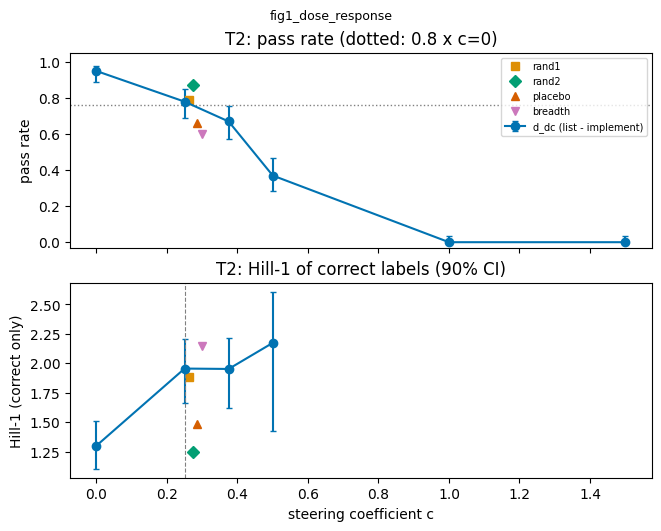

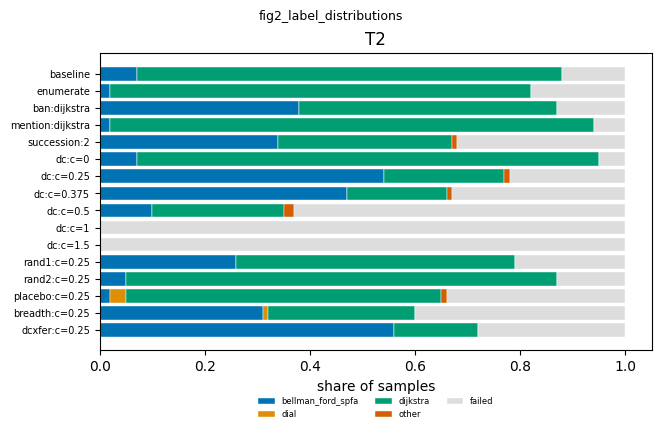

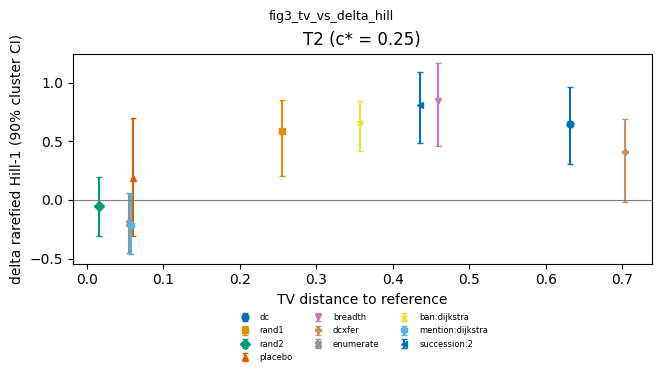

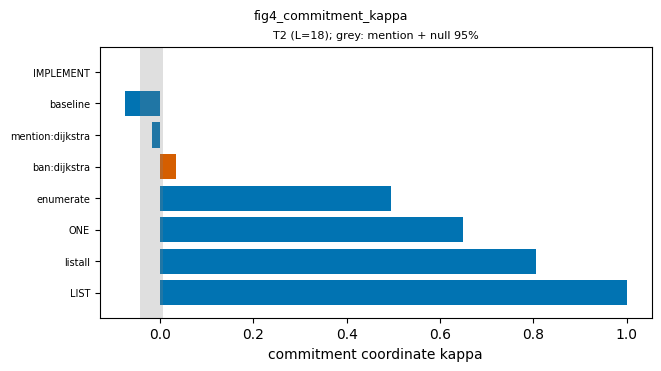

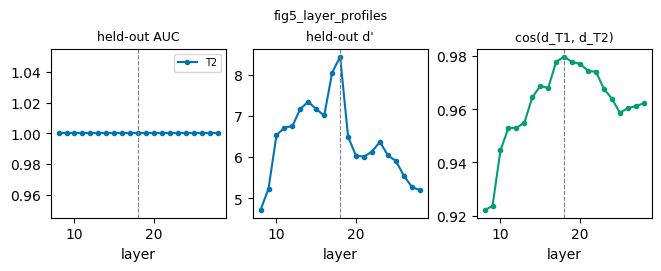

In [29]:
# ---- analysis/figures.py (subplot columns follow TASKS; figures shown inline) ----
plt.rcParams.update({"font.size": 10, "pdf.fonttype": 42})  # figures.py fallback when the house style is absent

C = ["#0173B2", "#DE8F05", "#029E73", "#D55E00", "#CC78BC", "#CA9161", "#949494", "#ECE133", "#56B4E9"]


def save(fig, name: str) -> None:
    # original: fig.savefig(FIGURES_DIR / f"{name}.pdf"); fig.savefig(FIGURES_DIR / f"{name}.png", dpi=160)
    fig.suptitle(name, fontsize=9)
    plt.show()
    plt.close(fig)


def fig1(summ: dict, cst: dict) -> None:
    L = cst["layer"]
    fig, axes = plt.subplots(2, len(TASKS), figsize=(6.5, 5.2), layout="constrained", sharex="col", squeeze=False)
    for j, t in enumerate(TASKS):
        cs = sorted(float(k) for k in cst[t]["pass_rates"])
        P, Plo, Phi, H, Hlo, Hhi, cx = [], [], [], [], [], [], []
        for c in cs:
            s = summ.get(f"{t}|steer:dc:c={c:g}:L={L}")
            if not s:
                continue
            cx.append(c)
            P.append(s["pass_rate"])
            Plo.append(s["pass_rate"] - s["wilson_ci"][0])
            Phi.append(s["wilson_ci"][1] - s["pass_rate"])
            h = s["hill_cc"]["hill1"]
            H.append(h if h is not None else float("nan"))
            ci = s.get("hill1_ci90_cluster") or [float("nan")] * 2
            Hlo.append((h - ci[0]) if h is not None else 0)
            Hhi.append((ci[1] - h) if h is not None else 0)
        ax = axes[0, j]
        ax.errorbar(cx, P, yerr=[Plo, Phi], marker="o", color=C[0], label="d_dc (list - implement)", capsize=2)
        ax.axhline(cst[t]["threshold"], ls=":", color="grey", lw=1)
        cstar = cst[t]["c_star"]
        for k, (nm, col, mk) in enumerate((("rand1", C[1], "s"), ("rand2", C[2], "D"), ("placebo", C[3], "^"),
                                           ("breadth", C[4], "v"))):
            s = summ.get(f"{t}|steer:{nm}:c={cstar:g}:L={L}")
            if s:
                ax.plot([cstar + 0.012 * (k + 1)], [s["pass_rate"]], mk, color=col, label=nm)
                h = s["hill_cc"]["hill1"]
                if h is not None:
                    axes[1, j].plot([cstar + 0.012 * (k + 1)], [h], mk, color=col)
        ax.set_title(f"{t}: pass rate (dotted: 0.8 x c=0)")
        ax.set_ylim(-0.03, 1.05)
        ax2 = axes[1, j]
        ax2.errorbar(cx, H, yerr=[Hlo, Hhi], marker="o", color=C[0], capsize=2)
        ax2.axvline(cstar, ls="--", color="grey", lw=0.8)
        ax2.set_title(f"{t}: Hill-1 of correct labels (90% CI)")
        ax2.set_xlabel("steering coefficient c")
        if j == 0:
            ax.set_ylabel("pass rate")
            ax2.set_ylabel("Hill-1 (correct only)")
    axes[0, -1].legend(fontsize=7, loc="upper right")  # original: axes[0, 1]
    save(fig, "fig1_dose_response")


def fig2(summ: dict, cst: dict, modes: dict) -> None:
    L = cst["layer"]
    fig, axes = plt.subplots(1, len(TASKS), figsize=(6.5, 4.2), layout="constrained", squeeze=False)
    for j, t in enumerate(TASKS):
        cs = cst[t]["c_star"]
        X = modes[t]["X"]
        arms = ["baseline", "enumerate", f"ban:{X}", f"mention:{X}", "succession:2"] + \
               [f"steer:dc:c={float(c):g}:L={L}" for c in sorted(float(k) for k in cst[t]["pass_rates"])] + \
               [f"steer:{n}:c={cs:g}:L={L}" for n in ("rand1", "rand2", "placebo", "breadth", "dcxfer")]
        arms = [a for a in arms if f"{t}|{a}" in summ]
        labs = sorted({k for a in arms for k in summ[f"{t}|{a}"]["label_counts_correct"]})
        ax = axes[0, j]
        left = [0.0] * len(arms)
        for i, lab in enumerate(labs + ["failed"]):
            vals = []
            for a in arms:
                s = summ[f"{t}|{a}"]
                vals.append((s["n"] - s["n_correct"]) / s["n"] if lab == "failed" else
                            s["label_counts_correct"].get(lab, 0) / s["n"])
            ax.barh(range(len(arms)), vals, left=left, color=("#DDDDDD" if lab == "failed" else C[i % len(C)]),
                    label=lab, edgecolor="white", lw=0.3)
            left = [l + v for l, v in zip(left, vals)]
        ax.set_yticks(range(len(arms)))
        ax.set_yticklabels([a.replace(f":L={L}", "").replace("steer:", "") for a in arms], fontsize=7)
        ax.invert_yaxis()
        ax.set_xlabel("share of samples")
        ax.set_title(t)
        ax.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)
    save(fig, "fig2_label_distributions")


def fig3(buy: dict, cst: dict) -> None:
    fig, axes = plt.subplots(1, len(TASKS), figsize=(6.5, 3.6), layout="constrained", sharey=True, squeeze=False)
    for j, t in enumerate(TASKS):
        ax = axes[0, j]
        cs = cst[t]["c_star"]
        quiet = []
        k_id = 0
        for k, v in buy[t].items():
            if k.startswith("_") or k in ("steer_vs_vllm_baseline", "enumerate@1024") or v.get("delta_hill_rarefied") is None:
                continue
            if k.startswith("steer:dc:") and f"c={cs:g}:" not in k:
                continue  # off-c* points of the dc curve are in fig1
            x, y = v.get("tv_to_reference"), v["delta_hill_rarefied"]
            ci = v.get("ci90_rarefied_cluster") or [y, y]
            name = k.replace("steer:", "").split(":L=")[0].replace(f":c={cs:g}", "")
            mk = "osD^vPX*h<>"[k_id % 11]
            ax.errorbar([x], [y], yerr=[[y - ci[0]], [ci[1] - y]], fmt=mk, color=C[k_id % len(C)], capsize=2, ms=5,
                        label=name)
            k_id += 1
            if abs(y) < 0.02 and x < 0.02:
                quiet.append(name)
        ax.axhline(0, color="grey", lw=0.8)
        ax.set_xlabel("TV distance to reference")
        ax.set_title(f"{t} (c* = {cs:g})")
        ax.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, frameon=False)
    axes[0, 0].set_ylabel("delta rarefied Hill-1 (90% cluster CI)")
    save(fig, "fig3_tv_vs_delta_hill")


def fig4(ct: dict, modes: dict) -> None:
    Ls = str(ct["layer_star"])
    fig, axes = plt.subplots(1, len(TASKS), figsize=(6.5, 3.6), layout="constrained", squeeze=False)
    for j, t in enumerate(TASKS):
        r = ct["per_task"][t][Ls]
        X = modes[t]["X"]
        keys = ["IMPLEMENT", "baseline", f"mention:{X}", f"ban:{X}", "enumerate", "ONE", "listall", "LIST"]
        vals = [r["kappa"][k] for k in keys]
        ax = axes[0, j]
        ax.barh(range(len(keys)), vals, color=[C[3] if k.startswith("ban") else C[0] for k in keys])
        b = r["ban"][X]
        lo, hi = b["null_band_95"]
        km = r["kappa"][f"mention:{X}"]
        ax.axvspan(km + lo, km + hi, color="grey", alpha=0.25, lw=0)
        ax.set_yticks(range(len(keys)))
        ax.set_yticklabels(keys, fontsize=7)
        ax.invert_yaxis()
        ax.set_xlabel("commitment coordinate kappa")
        ax.set_title(f"{t} (L={Ls}); grey: mention + null 95%", fontsize=8)
    save(fig, "fig4_commitment_kappa")


def fig5(sel: dict, diag: dict) -> None:
    ls = sorted(int(l) for l in sel["per_layer"])
    fig, axes = plt.subplots(1, 3, figsize=(6.5, 2.6), layout="constrained")
    for j, t in enumerate(TASKS):
        axes[0].plot(ls, [sel["per_layer"][str(l)][t]["auc"] for l in ls], marker=".", color=C[j], label=t)
        axes[1].plot(ls, [sel["per_layer"][str(l)][t]["dprime"] for l in ls], marker=".", color=C[j], label=t)
    axes[2].plot(ls, [diag["per_layer"][str(l)]["cross_task_cos"] for l in ls], marker=".", color=C[2])
    for ax, ttl in zip(axes, ("held-out AUC", "held-out d'", "cos(d_T1, d_T2)")):
        ax.set_title(ttl, fontsize=9)
        ax.set_xlabel("layer")
        ax.axvline(sel["L_star"], ls="--", color="grey", lw=0.8)
    axes[0].legend(fontsize=7)
    save(fig, "fig5_layer_profiles")


fig1(RESULTS["condition_summaries"], RESULTS["cstar"])
fig2(RESULTS["condition_summaries"], RESULTS["cstar"], modes)
fig3(RESULTS["buy_table"], RESULTS["cstar"])
fig4(RESULTS["commitment_test"], modes)
# fig5 from the full-run per-layer values (21 layers; the demo ships R-states at 3 of them)
rep_ls = data["reported"]["layer_selection"]
fig5({"L_star": rep_ls["L_star"], "per_layer": {l: {"T2": v} for l, v in rep_ls["per_layer"].items()}},
     {"per_layer": {l: {"cross_task_cos": v["cross_task_cos"]} for l, v in data["reported"]["direction_diagnostics"].items()}})

## Activation-space geometry at the read position (added visualisation)

These plots show the **actual 4096-d residual states at R (layer 18)** for all 440 T2 prompts, without summarising them first. Every point is one prompt.

* **Left: unsupervised PCA** of all states.
* **Right: a supervised plane.**
  * x is the commitment coordinate κ along `d_dc`: 0 is the IMPLEMENT-frame mean, 1 is the LIST-frame mean.
  * y is the `rand1` steering direction, orthogonalised to `d_dc`, in the same units (‖d_dc‖).
  * The arrows are the hook's displacement of the baseline centroid for c = 0.1 to 0.5, along `d_dc` (horizontal) and along `rand1` (vertical). The text gives the behaviour each arm produced at c*.

What the plots show:
* **In the PCA, the frames separate cleanly.** LIST, ONE, the two placebo frames and enumerate each form their own cloud. The baseline, IMPLEMENT, ban and mention prompts sit together: at R, banning or naming an algorithm barely changes the state.
* **The hook moves R farther than any prompt does.** The farthest prompt frame, LIST, is 1.16 ‖d_dc‖ from the baseline. The hook at c* moves R 1.36 ‖d_dc‖.
* **The same spot on the map, different behaviour.** rand1, rand2 and the placebo all land at the same spot: orthogonal to `d_dc`, at the same distance. Yet their programs differ: rand1 flips a third of the correct programs to Bellman-Ford, while rand2 and the placebo stay Dijkstra. The angle to `d_dc` alone cannot explain the T2 shift.

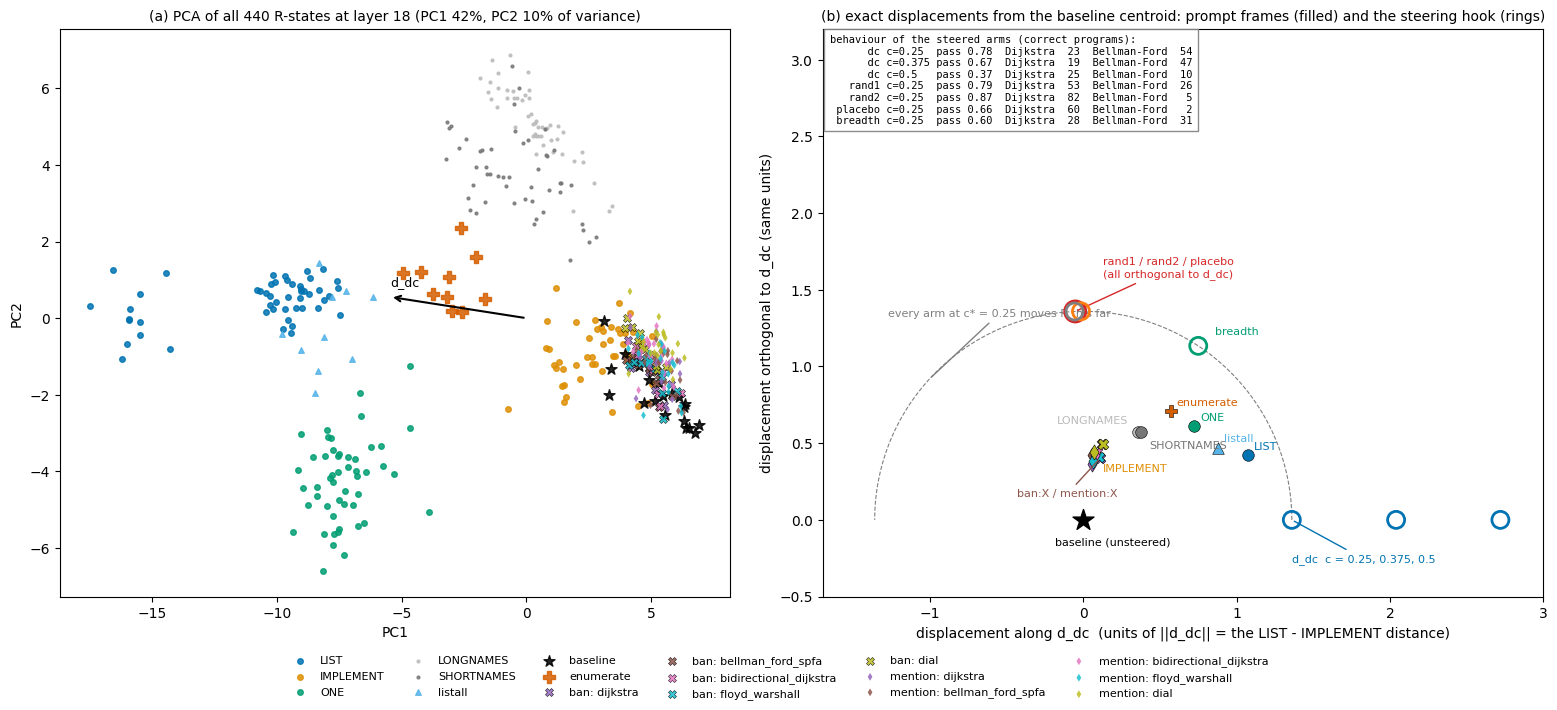

,group,mean kappa,along d_dc vs baseline,orthogonal vs baseline,distance from baseline
0,LIST,1.000,1.075,0.423,1.155
1,IMPLEMENT,-0.000,0.075,0.423,0.430
2,ONE,0.650,0.725,0.610,0.948
3,LONGNAMES,0.280,0.355,0.574,0.676
4,SHORTNAMES,0.299,0.374,0.572,0.684
5,listall,0.806,0.881,0.470,0.998
6,baseline,-0.075,0.000,0.000,0.000
7,enumerate,0.495,0.570,0.709,0.910
8,ban:dijkstra,0.035,0.110,0.402,0.417
9,ban:bellman_ford_spfa,0.047,0.122,0.493,0.507


||d_dc|| = 15.08, mean ||h_R|| = 82.00: at strength c the hook moves R by c*||h||/||d_dc|| = 5.44 c units (c* = 0.25 -> 1.36); the farthest prompt-group centroid (LIST) lies 1.16 units from the baseline


In [30]:
GROUP_STYLE = {"LIST": ("#0173B2", "o"), "IMPLEMENT": ("#DE8F05", "o"), "ONE": ("#029E73", "o"),
               "LONGNAMES": ("#BBBBBB", "."), "SHORTNAMES": ("#777777", "."), "listall": ("#56B4E9", "^"),
               "baseline": ("#000000", "*"), "enumerate": ("#D55E00", "P")}
ALG_COL = {"dijkstra": "#9467BD", "bellman_ford_spfa": "#8C564B", "bidirectional_dijkstra": "#E377C2",
           "floyd_warshall": "#17BECF", "dial": "#BCBD22"}
ARM_COL = {"dc": "#0173B2", "breadth": "#029E73", "rand1": "#D62728", "rand2": "#FF7F0E", "placebo": "#7F7F7F"}
geo_groups = list(GROUP_STYLE) + [f"ban:{m}" for m in CATALOGUE["T2"]] + [f"mention:{m}" for m in CATALOGUE["T2"]]
Hs = {g: load("T2", g)[:, Ls] for g in geo_groups}
allH = np.concatenate([Hs[g] for g in geo_groups])
mu_all = allH.mean(0)
_, sv, Vt_all = np.linalg.svd(allH - mu_all, full_matrices=False)
base_c = Hs["baseline"].mean(0)
hn_base = float(np.linalg.norm(Hs["baseline"], axis=1).mean())
cs_T2 = RESULTS["cstar"]["T2"]["c_star"]
summ_ = RESULTS["condition_summaries"]


def disp(delta: np.ndarray) -> tuple[float, float]:
    """Exact decomposition of a 4096-d displacement: (component along d_hat, norm of the rest), in units of ||d_dc||."""
    a = float(delta @ dhat_L)
    return a / dnorm_L, float(np.linalg.norm(delta - a * dhat_L)) / dnorm_L


fig, axes = plt.subplots(1, 2, figsize=(16, 7), layout="constrained", gridspec_kw={"width_ratios": [1, 1.25]})
# (left) unsupervised PCA of every prompt state
ax = axes[0]
for g in geo_groups:
    P2 = (Hs[g] - mu_all) @ Vt_all[:2].T
    if g.startswith(("ban:", "mention:")):
        kind, m = g.split(":")
        ax.scatter(P2[:, 0], P2[:, 1], s=34 if kind == "ban" else 16, marker="X" if kind == "ban" else "d",
                   color=ALG_COL[m], edgecolor="k" if kind == "ban" else "none", lw=0.4, alpha=0.85, label=f"{kind}: {m}")
    else:
        col, mk = GROUP_STYLE[g]
        ax.scatter(P2[:, 0], P2[:, 1], s=70 if g in ("baseline", "enumerate") else 16, marker=mk, color=col,
                   alpha=0.85, label=g)
dpc = Vt_all[:2] @ dhat_L
ax.annotate("", xy=(dpc[0] * 6, dpc[1] * 6), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="k", lw=1.5))
ax.text(dpc[0] * 6, dpc[1] * 6 + 0.3, "d_dc", fontsize=9)
ax.set_title(f"(a) PCA of all {len(allH)} R-states at layer {lstar} (PC1 {sv[0]**2 / (sv**2).sum():.0%}, "
             f"PC2 {sv[1]**2 / (sv**2).sum():.0%} of variance)", fontsize=10)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")

# (right) displacement of every prompt-group centroid and of the hook's edit, relative to the baseline centroid
ax = axes[1]
for g in geo_groups:
    if g == "baseline":
        continue
    a, o = disp(Hs[g].mean(0) - base_c)
    if g.startswith(("ban:", "mention:")):
        kind, m = g.split(":")
        ax.scatter(a, o, marker="X" if kind == "ban" else "d", s=60, color=ALG_COL[m], edgecolor="k", lw=0.4)
    else:
        col, mk = GROUP_STYLE[g]
        ax.scatter(a, o, marker=mk if mk != "." else "o", s=70, color=col, edgecolor="k", lw=0.4)
        ax.annotate(g, (a, o), xytext={"IMPLEMENT": (6, -12), "LONGNAMES": (-58, 6), "SHORTNAMES": (6, -12)}.get(g, (4, 4)),
                    textcoords="offset points", fontsize=8, color=col)
ax.annotate("ban:X / mention:X", disp(Hs["ban:dijkstra"].mean(0) - base_c), xytext=(-60, -28),
            textcoords="offset points", fontsize=8, color="#8C564B", arrowprops=dict(arrowstyle="-", color="#8C564B"))
ax.scatter(0, 0, marker="*", s=250, color="k", zorder=6)
ax.annotate("baseline (unsteered)", (0, 0), xytext=(-20, -18), textcoords="offset points", fontsize=8)
r_star = cs_T2 * hn_base / dnorm_L
th = np.linspace(0, np.pi, 200)
ax.plot(r_star * np.cos(th), r_star * np.sin(th), ls="--", color="grey", lw=0.8)
ax.annotate(f"every arm at c* = {cs_T2:g} moves R this far", (r_star * np.cos(2.4), r_star * np.sin(2.4)),
            xytext=(-30, 45), textcoords="offset points", fontsize=8, color="grey",
            arrowprops=dict(arrowstyle="-", color="grey"))
ring_txt = ["behaviour of the steered arms (correct programs):"]
for name, vec in STEER_VECS.items():
    vhat = vec / np.linalg.norm(vec)
    for c in ([0.25, 0.375, 0.5] if name == "dc" else [cs_T2]):
        s = summ_.get(f"T2|steer:{name}:c={c:g}:L={lstar}")
        if s is None:
            continue
        a, o = disp(c * hn_base * vhat)  # the hook adds c ||h|| v_hat at R
        lc = s["label_counts_correct"]
        ax.scatter(a, o, marker="o", s=150 if name != "rand1" else 230, facecolor="none", edgecolor=ARM_COL[name],
                   lw=2, zorder=5)
        ring_txt.append(f"{name:>8s} c={c:<5g} pass {s['pass_rate']:.2f}  Dijkstra {lc.get('dijkstra', 0):3d}  "
                        f"Bellman-Ford {lc.get('bellman_ford_spfa', 0):3d}")
ax.annotate("rand1 / rand2 / placebo\n(all orthogonal to d_dc)", disp(cs_T2 * hn_base * STEER_VECS["rand1"]
                                                                   / np.linalg.norm(STEER_VECS["rand1"])),
            xytext=(20, 25), textcoords="offset points", fontsize=8, color=ARM_COL["rand1"],
            arrowprops=dict(arrowstyle="-", color=ARM_COL["rand1"]))
ax.annotate("breadth", disp(cs_T2 * hn_base * STEER_VECS["breadth"] / np.linalg.norm(STEER_VECS["breadth"])),
            xytext=(12, 8), textcoords="offset points", fontsize=8, color=ARM_COL["breadth"])
ax.annotate("d_dc  c = 0.25, 0.375, 0.5", (r_star, 0), xytext=(0, -30), textcoords="offset points", fontsize=8,
            color=ARM_COL["dc"], arrowprops=dict(arrowstyle="-", color=ARM_COL["dc"]))
ax.text(0.01, 0.99, "\n".join(ring_txt), transform=ax.transAxes, ha="left", va="top", family="monospace", fontsize=7.5,
        bbox=dict(fc="white", ec="grey", alpha=0.9))
ax.set_xlim(-1.7, 3.0)
ax.set_ylim(-0.5, 3.2)
ax.set_aspect("equal")
ax.set_xlabel("displacement along d_dc  (units of ||d_dc|| = the LIST - IMPLEMENT distance)")
ax.set_ylabel("displacement orthogonal to d_dc (same units)")
ax.set_title("(b) exact displacements from the baseline centroid: prompt frames (filled) and the steering hook (rings)",
             fontsize=10)
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="outside lower center", ncol=6, fontsize=8, frameon=False)
plt.show()

disp_tab = pd.DataFrame([{"group": g, "mean kappa": round(float(kappa_of(Hs[g]).mean()), 3),
                          "along d_dc vs baseline": round(disp(Hs[g].mean(0) - base_c)[0], 3),
                          "orthogonal vs baseline": round(disp(Hs[g].mean(0) - base_c)[1], 3),
                          "distance from baseline": round(float(np.hypot(*disp(Hs[g].mean(0) - base_c))), 3)}
                         for g in geo_groups])
display(disp_tab)
far = disp_tab.loc[disp_tab["distance from baseline"].idxmax()]
print(f"||d_dc|| = {dnorm_L:.2f}, mean ||h_R|| = {hn_base:.2f}: at strength c the hook moves R by c*||h||/||d_dc|| = "
      f"{hn_base / dnorm_L:.2f} c units (c* = {cs_T2:g} -> {r_star:.2f}); the farthest prompt-group centroid "
      f"({far['group']}) lies {far['distance from baseline']:.2f} units from the baseline")

### The algorithm-name map, and does a paraphrase's position predict the steering outcome?

* **Left.** The PCA of the 100 `mention:X` states ("X is one well-known approach to this task; implement any correct algorithm"), 20 paraphrases for each of the 5 T2 algorithms. The 50 `ban:X` states ("Do not use X.") are projected into the same PCA. This is how the model's state at R encodes *which* algorithm the prompt named.
* **Middle.** Classical MDS of the group centroids. Marker size shows how often the model *writes* each algorithm unprompted (HF c=0, correct programs). Banning Dijkstra made **every** compliant program in the full run Bellman-Ford (38 / 38). The printed table asks whether Bellman-Ford is also the named algorithm whose state lies nearest to Dijkstra's.
* **Right.** For each of the 10 HF baseline paraphrases: its κ, against the share of its correct programs that are *not* Dijkstra, at c = 0, under d_dc at c* and under rand1 at c*. This is exploratory: n = 10 paraphrases, Spearman ρ printed.

What the plots show:
* **Left.** Once the template is centred out, the five names form five separate clusters at R. Each `ban:X` name effect lands on its `mention:X` cluster, with cos(e_mention, e_ban) between 0.62 and 0.80. So the model encodes *which* algorithm was named, consistently across the two contexts.
* **Middle and table.** Bellman-Ford, the algorithm the model switches to when Dijkstra is banned, is the **farthest** named algorithm from Dijkstra in this name geometry; Floyd-Warshall is the nearest. The substitution does not follow nearest-neighbour distance between the encoded names.
* **Right.** A paraphrase's unsteered κ does not predict how often its programs leave Dijkstra, with or without steering (all |ρ| ≤ 0.31, p ≥ 0.39).

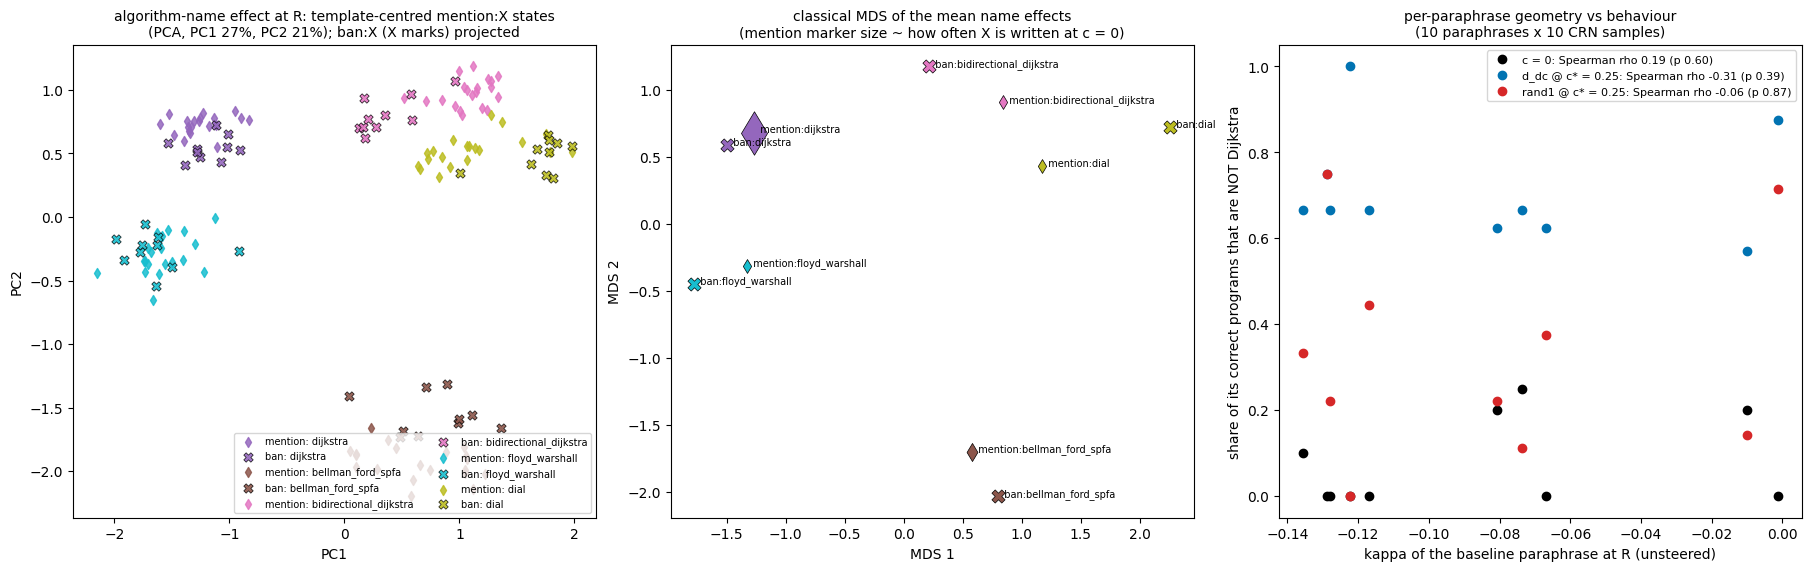

,named algorithm X,"||e(X) - e(dijkstra)||, mention","||e(X) - e(dijkstra)||, ban","cos(e_mention(X), e_ban(X))",correct programs at c = 0 (HF),compliant programs under ban:dijkstra (demo)
0,dijkstra,0.000,0.000,0.800,88,0
1,bellman_ford_spfa,3.311,3.729,0.734,7,38
2,bidirectional_dijkstra,2.754,2.759,0.619,0,0
3,floyd_warshall,2.100,2.346,0.786,0,0
4,dial,3.106,4.200,0.670,0,0


named algorithms ordered by name-effect distance from Dijkstra (mention context): ['floyd_warshall', 'bidirectional_dijkstra', 'dial', 'bellman_ford_spfa']


,arm,Spearman rho,p
0,c = 0,0.192,0.595
1,d_dc @ c* = 0.25,-0.307,0.388
2,rand1 @ c* = 0.25,-0.061,0.868


In [31]:
from scipy.stats import spearmanr

ALGS = CATALOGUE["T2"]
# name effects: every paraphrase template is centred across the 5 algorithms, so only the algorithm NAME varies
E = {}
for kind in ("mention", "ban"):
    stack = np.stack([Hs[f"{kind}:{m}"] for m in ALGS])  # [5 algorithms, n templates, 4096]
    E[kind] = stack - stack.mean(0, keepdims=True)
_, sv_m, Vt_m = np.linalg.svd(E["mention"].reshape(-1, D_MODEL), full_matrices=False)
eff = {k: {m: E[k][i].mean(0) for i, m in enumerate(ALGS)} for k in E}  # mean name effect of X per context
impl_counts = summ_[f"T2|steer:dc:c=0:L={lstar}"]["label_counts_correct"]
ban_comp = Counter(r["label"] for r in by[("T2", "ban:dijkstra")] if r["compliant"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), layout="constrained")
# (left) PCA of the template-centred mention:X states; ban:X name effects projected into the same plane
ax = axes[0]
for i, m in enumerate(ALGS):
    Pm, Pb = E["mention"][i] @ Vt_m[:2].T, E["ban"][i] @ Vt_m[:2].T
    ax.scatter(Pm[:, 0], Pm[:, 1], marker="d", s=26, color=ALG_COL[m], alpha=0.85, label=f"mention: {m}")
    ax.scatter(Pb[:, 0], Pb[:, 1], marker="X", s=46, color=ALG_COL[m], edgecolor="k", lw=0.5, alpha=0.9, label=f"ban: {m}")
ax.set_title(f"algorithm-name effect at R: template-centred mention:X states\n(PCA, PC1 {sv_m[0]**2 / (sv_m**2).sum():.0%}, "
             f"PC2 {sv_m[1]**2 / (sv_m**2).sum():.0%}); ban:X (X marks) projected", fontsize=10)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(fontsize=7, ncol=2, loc="lower right")

# (middle) classical MDS of the 10 mean name effects (5 algorithms x {mention, ban})
cnames = [(k, m) for k in ("mention", "ban") for m in ALGS]
Cm = np.stack([eff[k][m] for k, m in cnames])
D2 = ((Cm[:, None, :] - Cm[None, :, :]) ** 2).sum(-1)
J = np.eye(len(Cm)) - 1.0 / len(Cm)
w_mds, V_mds = np.linalg.eigh(-0.5 * J @ D2 @ J)
top2 = np.argsort(w_mds)[::-1][:2]
Y = V_mds[:, top2] * np.sqrt(np.maximum(w_mds[top2], 0))
ax = axes[1]
for i, (k, m) in enumerate(cnames):
    ax.scatter(*Y[i], marker="d" if k == "mention" else "X", color=ALG_COL[m], edgecolor="k", lw=0.5,
               s=(50 + 5 * impl_counts.get(m, 0)) if k == "mention" else 90)
    ax.text(*Y[i], f"  {k}:{m}", fontsize=7)
ax.set_title("classical MDS of the mean name effects\n(mention marker size ~ how often X is written at c = 0)", fontsize=10)
ax.set_xlabel("MDS 1")
ax.set_ylabel("MDS 2")

# (right) does a paraphrase's starting kappa predict how far steering moves its programs?
ax = axes[2]
kap_p = kappa_of(Hs["baseline"][:10])  # HF arms use baseline paraphrases 0-9
rho_rows = []
for name, cond, col in (("c = 0", f"steer:dc:c=0:L={lstar}", "k"),
                        (f"d_dc @ c* = {cs_T2:g}", f"steer:dc:c={cs_T2:g}:L={lstar}", ARM_COL["dc"]),
                        (f"rand1 @ c* = {cs_T2:g}", f"steer:rand1:c={cs_T2:g}:L={lstar}", ARM_COL["rand1"])):
    share = []
    for p in range(10):
        corr = [r for r in by[("T2", cond)] if r["paraphrase_id"] == p and r["passed"]]
        share.append(float(np.mean([r["label"] != "dijkstra" for r in corr])) if corr else np.nan)
    share = np.array(share)
    ok = ~np.isnan(share)
    rho, pval = spearmanr(kap_p[ok], share[ok]) if len(set(share[ok].tolist())) > 1 else (np.nan, np.nan)
    rho_rows.append({"arm": name, "Spearman rho": round(float(rho), 3), "p": round(float(pval), 3)})
    ax.plot(kap_p, share, "o", color=col, label=f"{name}: Spearman rho {rho:.2f} (p {pval:.2f})")
ax.set_xlabel("kappa of the baseline paraphrase at R (unsteered)")
ax.set_ylabel("share of its correct programs that are NOT Dijkstra")
ax.set_title("per-paraphrase geometry vs behaviour\n(10 paraphrases x 10 CRN samples)", fontsize=10)
ax.legend(fontsize=8)
plt.show()

dist_tab = pd.DataFrame([{"named algorithm X": m,
                          "||e(X) - e(dijkstra)||, mention": float(np.linalg.norm(eff["mention"][m] - eff["mention"]["dijkstra"])),
                          "||e(X) - e(dijkstra)||, ban": float(np.linalg.norm(eff["ban"][m] - eff["ban"]["dijkstra"])),
                          "cos(e_mention(X), e_ban(X))": cos(eff["mention"][m], eff["ban"][m]),
                          "correct programs at c = 0 (HF)": impl_counts.get(m, 0),
                          "compliant programs under ban:dijkstra (demo)": ban_comp.get(m, 0)} for m in ALGS]).round(3)
display(dist_tab)
order = dist_tab[dist_tab["named algorithm X"] != "dijkstra"].sort_values("||e(X) - e(dijkstra)||, mention")
print("named algorithms ordered by name-effect distance from Dijkstra (mention context):",
      order["named algorithm X"].tolist())
display(pd.DataFrame(rho_rows))

## Summary: the headline numbers, recomputed against the full run

With the config at the original repeat counts (the default), every HF-referenced number matches the full run exactly: pass rates, label counts, c*, ΔHill-1 with its cluster CI, the dc − random specificity test, δκ and its null band, and the sign-flip p. The expected differences are:
* the vLLM-baseline-referenced rows (enumerate, ban, mention, succession), because the demo ships 100 of the baseline's 200 samples;
* the 4th decimal of the label-permutation p.

In [32]:
cs = RESULTS["cstar"]["T2"]["c_star"]
k0, k_dc, k_r1 = f"steer:dc:c=0:L={lstar}", f"steer:dc:c={cs:g}:L={lstar}", f"steer:rand1:c={cs:g}:L={lstar}"
sm, rs = RESULTS["condition_summaries"], data["reported"]["condition_summaries"]
bt, rb = RESULTS["buy_table"]["T2"], data["reported"]["buy_table"]
ctb, rct = RESULTS["commitment_test"]["per_task"]["T2"][str(lstar)], data["reported"]["commitment_test_Lstar"]
sp, rsp = RESULTS["screen_verdict"]["per_task"]["T2"], data["reported"]["screen_verdict"]["T2"]
au, rau = RESULTS["audit_commitment_perm"]["T2"], data["reported"]["audit_commitment_perm"]


def dh(b: dict) -> str:  # "+0.65 [0.31, 0.97]"
    ci = b.get("ci90_rarefied_cluster")
    return "-" if b.get("delta_hill_rarefied") is None else f"{b['delta_hill_rarefied']:+.2f} [{ci[0]:.2f}, {ci[1]:.2f}]"


rows_sum = [
    ("L* (held-out AUC, d' tie-break)", lstar, data["reported"]["layer_selection"]["L_star"]),
    ("c* (largest c with pass >= 0.8 x pass(c=0))", cs, PIPELINE["cstar"]["T2"]["c_star"]),
    ("pass rate: HF c=0 / d_dc @ c* / rand1 @ c*",
     " / ".join(f"{sm['T2|' + k]['pass_rate']:.2f}" for k in (k0, k_dc, k_r1)),
     " / ".join(f"{rs[k]['pass_rate']:.2f}" for k in (k0, k_dc, k_r1))),
    ("correct labels: HF c=0", sm["T2|" + k0]["label_counts_correct"], rs[k0]["label_counts_correct"]),
    ("correct labels: d_dc @ c*", sm["T2|" + k_dc]["label_counts_correct"], rs[k_dc]["label_counts_correct"]),
    ("correct labels: rand1 @ c*", sm["T2|" + k_r1]["label_counts_correct"], rs[k_r1]["label_counts_correct"]),
    ("correct labels: vLLM baseline", sm["T2|baseline"]["label_counts_correct"], rs["baseline"]["label_counts_correct"]),
    ("correct labels: ban:dijkstra", sm["T2|ban:dijkstra"]["label_counts_correct"], rs["ban:dijkstra"]["label_counts_correct"]),
    ("dHill-1 rarefied, d_dc @ c* [90% cluster CI]", dh(bt[k_dc]), dh(rb[k_dc])),
    ("dHill-1 rarefied, rand1 @ c*", dh(bt[k_r1]), dh(rb[k_r1])),
    ("dHill-1 rarefied, ban:dijkstra", dh(bt["ban:dijkstra"]), dh(rb["ban:dijkstra"])),
    ("dHill-1 rarefied, enumerate", dh(bt["enumerate"]), dh(rb["enumerate"])),
    ("specificity d_dc - rand1 [90% CI]",
     f"{sp['specificity']['rand1']['point']:+.2f} [{sp['specificity']['rand1']['ci90'][0]:.2f}, {sp['specificity']['rand1']['ci90'][1]:.2f}]",
     f"{rsp['specificity']['rand1']['point']:+.2f} [{rsp['specificity']['rand1']['ci90'][0]:.2f}, {rsp['specificity']['rand1']['ci90'][1]:.2f}]"),
    ("commitment: delta kappa ban - mention (dijkstra)", round(ctb["ban"]["dijkstra"]["delta_kappa"], 4),
     round(rct["ban"]["dijkstra"]["delta_kappa"], 4)),
    ("commitment: exact sign-flip p / label-permutation p",
     f"{au['paired_signflip_p_exact']:.3f} / {au['unpaired_label_perm_p']:.3f}",
     f"{rau['paired_signflip_p_exact']:.3f} / {rau['unpaired_label_perm_p']:.3f}"),
    ("commitment: enumerate positive control delta kappa", round(ctb["positive_control"]["enum_delta_kappa"], 4),
     round(rct["positive_control"]["enum_delta_kappa"], 4)),
    ("S_flat / S_specific / S_commit", f"{sp['S_flat']} / {sp['S_specific']} / {sp['S_commit']}",
     f"{rsp['S_flat']} / {rsp['S_specific']} / {rsp['S_commit']}"),
    ("screen verdict", f"{RESULTS['screen_verdict']['overall']} (T2 only)",
     f"{data['reported']['screen_verdict']['overall_both_tasks']} (T1 + T2)"),
]
display(pd.DataFrame([(q, str(a), str(b)) for q, a, b in rows_sum], columns=["quantity (T2)", "this notebook", "full run"]))

,quantity (T2),this notebook,full run
0,"L* (held-out AUC, d' tie-break)",18,18
1,c* (largest c with pass >= 0.8 x pass(c=0)),0.25,0.25
2,pass rate: HF c=0 / d_dc @ c* / rand1 @ c*,0.95 / 0.78 / 0.79,0.95 / 0.78 / 0.79
3,correct labels: HF c=0,"{'dijkstra': 88, 'bellman_ford_spfa': 7}","{'dijkstra': 88, 'bellman_ford_spfa': 7}"
4,correct labels: d_dc @ c*,"{'bellman_ford_spfa': 54, 'dijkstra': 23, 'other': 1}","{'bellman_ford_spfa': 54, 'dijkstra': 23, 'other': 1}"
5,correct labels: rand1 @ c*,"{'dijkstra': 53, 'bellman_ford_spfa': 26}","{'dijkstra': 53, 'bellman_ford_spfa': 26}"
6,correct labels: vLLM baseline,"{'dijkstra': 81, 'bellman_ford_spfa': 7}","{'dijkstra': 169, 'bellman_ford_spfa': 8}"
7,correct labels: ban:dijkstra,"{'dijkstra': 49, 'bellman_ford_spfa': 38}","{'dijkstra': 49, 'bellman_ford_spfa': 38}"
8,"dHill-1 rarefied, d_dc @ c* [90% cluster CI]","+0.65 [0.31, 0.97]","+0.65 [0.31, 0.97]"
9,"dHill-1 rarefied, rand1 @ c*","+0.59 [0.21, 0.85]","+0.59 [0.21, 0.85]"


## What the demo shows, and how to go further

* **Monoculture.** Unsteered, Qwen3-8B writes Dijkstra for nearly every correct T2 program. In the full run T1 was 100 % BFS in every arm except the bans. The enumeration prompt ("list 10 approaches, then implement one") does not change this.
* **Steering moves the mode; it does not specifically "de-commit".** At c* = 0.25, `d_dc` turns most correct programs into Bellman-Ford (54 of 78), and Hill-1 rises by +0.65. A norm-matched random direction (`rand1`), orthogonal to `d_dc`, raises Hill-1 almost as much (+0.59; dc − rand1 = +0.07 [−0.26, 0.39]), so the gain is not specific to the list-vs-implement axis. The geometry plots show why this reading is natural. The hook moves the read-position state farther than any prompt frame does, and a push of that size can knock the model off a fragile Dijkstra commitment. Whether it does depends on the particular direction (rand1 does; rand2 and the placebo do not), not on the direction's angle to `d_dc`.
* **Prompt bans substitute rather than subtract.** Banning Dijkstra yields Bellman-Ford, not a spread over the catalogue, and many banned samples still use Dijkstra. At R, the ban shifts the state only slightly toward the LIST frame. That shift is significant on exact tests but tiny next to the enumeration prompt.

**Full run.** The full pipeline (`method.py`: GPU generation, sandboxed hidden tests, runtime tracer, LLM judge) needs Qwen3-8B on a ≥ 20 GB GPU, about 2.1 GPU-hours and an OpenRouter key; see `reproducibility.md` of the experiment. Its T2 outputs are what this notebook re-analyses. With the config at its original values (the default here), every HF-referenced statistic matches the full run exactly. Task T1 (100 % BFS) is not shipped, to keep the demo to one dataset.